# 세그멘테이션 파일별 1 · 코드잇 Segmentation 강의 (픽셀 분류 · FCN · U-Net · Mask R-CNN)

**한 줄 요약**

- PDF 62쪽을 순서대로 따라가며 '픽셀마다 분류'가 왜 어렵고, FCN · U-Net
- Mask R-CNN이 그 문제를 어떻게 푸는지 작은 텐서로 직접 계산해 확인 (원본은 개념 슬라이드라 코드는 모두 보강)

- **원본** · `7. 딥러닝/05_Segmentation/강의자료/코드잇_Segmentation.pdf` (원본 파일은 그대로 둠)
- **종합 정리본** · `00_최소선/12_세그멘테이션` 세그멘테이션-1 (픽셀 분류 · U-Net) · 세그멘테이션-2 4장 (Instance)

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. semantic · instance · panoptic 분할의 정답 모양을 작은 지도로 만들어 구분한다
2. 패치를 잘라 분류하는 방법과 합성곱 한 번이 같은 계산임을 보이고, 왜 FCN이 효율적인지 설명한다
3. nearest · bed of nails · max unpooling · 이중 선형 보간 · 전치 합성곱을 손으로 계산해 코드와 맞춘다
4. FCN의 완전 연결층 → 합성곱 변환과 skip(32s · 16s · 8s)이 경계를 되살리는 이유를 숫자로 설명한다
5. U-Net 원 논문의 572 → 388 크기 변화와 RoIAlign · 마스크 헤드의 동작을 코드로 확인한다

## 어디에 쓰나

*실제 상황 → 이 권에서 배우는 것*

- **의료 영상 · 위성 사진처럼 영역 경계가 답일 때** · 픽셀 분류 · U-Net (1 · 5장)
- **분류용 CNN을 분할 모델로 바꿔야 할 때** · 완전 연결층 → 합성곱 · 1×1 점수 (4장)
- **디코더에서 어떤 업샘플링을 쓸지 고를 때** · 보간 · unpooling · 전치 합성곱 비교 (3장)
- **큰 사진을 잘라 추론할 때** · overlap-tile · mirroring (5장)
- **개체마다 마스크가 필요할 때** · Mask R-CNN · RoIAlign (6장)

## 학습 지도

<img src="images/sf1_map.png" alt="코드잇_Segmentation 학습 지도" width="763">

**예상 학습 시간** · 개념 2시간 + 실습 40분 (7장 학습은 GPU 약 1분 · CPU만 있으면 약 10분)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td>0</td><td>준비</td><td>실행 환경 · 원본 목표</td></tr>
<tr><td>1</td><td>Image Segmentation이란</td><td>분할은 픽셀마다 무엇을 답하고, 세 종류는 무엇이 다른가?</td></tr>
<tr><td>2</td><td>픽셀을 어떻게 분류할까</td><td>픽셀마다 패치를 잘라 분류하면 무엇이 비효율적이고, 합성곱은 무엇이 다른가?</td></tr>
<tr><td>3</td><td>다운샘플링과 업샘플링</td><td>줄어든 특징 지도를 원래 크기로 키우는 방법은 무엇이 있고, 무엇이 다른가?</td></tr>
<tr><td>4</td><td>FCN</td><td>분류 CNN을 어떻게 바꾸면 임의 크기 입력에 픽셀마다 점수를 내는가?</td></tr>
<tr><td>5</td><td>U-Net</td><td>U-Net은 FCN의 무엇을 보완하고, 원 논문은 입력 · 데이터 · 손실을 어떻게 다뤘는가?</td></tr>
<tr><td>6</td><td>Instance Segmentation · Mask R-CNN</td><td>Mask R-CNN은 Faster R-CNN에 무엇을 더해 개체마다 마스크를 내는가?</td></tr>
<tr><td>7</td><td>종합 실습</td><td>같은 인코더 · 같은 조건에서 디코더만 바꾸면 mIoU와 경계 정확도는?</td></tr>
<tr><td>—</td><td>마무리 · 부록</td><td>오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td></tr>
</tbody></table>

---
## 0. 준비

원본은 개념 슬라이드(PDF)라 실행 코드가 없음 → **모든 코드는 보강**. 데이터 파일은 필요 없음 (작은 텐서 · 노트북 안에서 그린 도형). **셀은 위에서부터 차례로 실행**.

*항목 → 설정*

- **라이브러리** · torch · torchvision (ops · v2) · numpy · scipy(거리 계산) · matplotlib
- **seed** · 42 · `cudnn.deterministic = True` · `benchmark = False`
- **장치** · GPU가 있으면 cuda, 없으면 cpu (7장만 학습 · 나머지는 작은 계산)
- **원본** · 코드잇 스프린트 Part 2 · Segmentation (PDF 62쪽 · 이미지만 있는 쪽은 그림으로 확인)

**실행 흐름**

1. 환경 변수 · 도구 불러오기
2. seed 고정 · 결정적 설정
3. 장치 · 버전 출력

In [1]:
# 실행 환경: 모든 코드는 보강 (원본 PDF에는 실행 코드가 없음)
# 왜 · PDF 설명을 직접 실행해 확인할 수 있게 도구 · seed · 장치를 한곳에서 정하기 위해
import os      # 환경 변수
import random  # 파이썬 난수

# 왜 · torch와 numpy를 한 커널에서 쓸 때 커널이 멈추는 충돌을 막기 위해
if "KMP_DUPLICATE_LIB_OK" not in os.environ:           # Windows Anaconda 충돌 방지
    os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"        # numpy · torch OpenMP 중복 허용
if "CUBLAS_WORKSPACE_CONFIG" not in os.environ:        # 같은 GPU · 같은 버전에서 행렬 곱도 같은 값
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # 결정적 cuBLAS 작업 공간

import numpy as np               # 배열 · 도형 그리기
import torch                     # 텐서 · 모델
import torch.nn.functional as F  # 보간 · 손실 함수
import torchvision               # roi_align · v2 증강
from torch import nn             # 층 만들기

# 왜 · python · numpy · torch 난수를 한 기준값으로 고정하기 위해
SEED = 42                                                              # 난수 기준값
random.seed(SEED)                                                      # 파이썬 random 고정
np.random.seed(SEED)                                                   # numpy 고정
torch.manual_seed(SEED)                                                # torch 고정 (CPU · GPU)
torch.backends.cudnn.deterministic = True                              # 같은 GPU · 같은 버전에서 합성곱도 같은 값
torch.backends.cudnn.benchmark = False                                 # 계산 방법이 바뀌지 않게
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU 있으면 GPU
print("torch", torch.__version__.split("+")[0], "· torchvision",       # 버전 기록
      torchvision.__version__.split("+")[0], "· device:", device.type)

torch 2.11.0 · torchvision 0.26.0 · device: cuda


### 원본 목차 (PDF 3단원)

- **01 Segmentation** (3 ~ 5쪽) · 픽셀마다 클래스 라벨 · semantic / instance / panoptic · one-hot 라벨
- **02 Semantic Segmentation** (7 ~ 42쪽) · 픽셀 · 패치 분류 아이디어 → 다운 · 업샘플링 → FCN → U-Net
- **03 Instance Segmentation** (43 ~ 62쪽) · semantic vs instance → Mask R-CNN (RoIAlign · 다중 작업 손실 · 후처리)

**원본 힌트**

- 원본 쪽 번호 = PDF 파일의 쪽 번호 (슬라이드 오른쪽 위 번호와 다를 수 있음)
- 수식 · 구조 그림만 있는 쪽(13 · 16 · 17 · 23 · 30 · 38 · 39쪽 등)은 이 노트북의 장 그림 · 손계산으로 옮김

---
## 1. Image Segmentation이란

> **이 장의 흐름**
>
> - 분류는 사진 한 장에 라벨 하나 → 분할은 픽셀마다 라벨
> - 같은 클래스 개체를 구분하느냐에 따라 semantic · instance · panoptic

<img src="images/sf1_kinds.png" alt="같은 장면의 semantic · instance · panoptic 정답" width="763">

**파이프라인 위치** · ① 문제 정의 → ② 정답 형식

### 1-1. `A` 세 가지 분할의 정답 · `semantic` · `instance` · `panoptic` <sub>PDF 3 · 4쪽</sub>

> 🎯 **차 두 대가 붙은 장면을 semantic · instance · panoptic은 각각 어떻게 답하는가?**

💡 **쉽게 말하면**

- semantic은 **색칠 공부** 한 장 · 같은 클래스는 같은 색.
- instance는 **차마다 따로 오린 스티커** · 셀 수 있는 것만.
- panoptic은 둘을 합쳐 **모든 칸에 (클래스, 번호)**.

**실행 흐름**

1. 6×8 장면에 하늘 · 도로 · 차 2대 칠하기
2. 차마다 마스크 목록 만들기
3. 모든 픽셀에 (클래스, 개체) 쌍 매기기

**먼저 예측** · 의미 분할 지도만 보고 차가 몇 대인지 알 수 있을까? — 답은 코드 실행 결과 아래에

In [2]:
# 같은 장면(6×8)을 세 가지 분할 정답으로 나타내기 (0 하늘 · 1 도로 · 2 차)
# 왜 · 세 분할 방식의 정답 형식 차이를 같은 장면으로 비교하기 위해
sem = torch.zeros(6, 8, dtype=torch.long)  # 의미 분할 지도
sem[3:, :] = 1                             # 아래 세 줄 = 도로
sem[2:5, 1:3] = 2                          # 차 A
sem[2:5, 3:5] = 2                          # 차 B (A와 붙어 있음)
print(sem)                                 # 픽셀마다 클래스 번호


# 인스턴스: 셀 수 있는 것(차)만 개체마다 마스크 한 장
# 왜 · 인스턴스 분할은 셀 수 있는 개체만 따로 나눈다는 것을 보이기 위해
car_a = torch.zeros(6, 8, dtype=torch.bool)              # 차 A 마스크
car_a[2:5, 1:3] = True                                   # A 자리
car_b = torch.zeros(6, 8, dtype=torch.bool)              # 차 B 마스크
car_b[2:5, 3:5] = True                                   # B 자리
instances = [("car", car_a), ("car", car_b)]             # (클래스, 마스크) 목록
print("의미 분할로 본 차 픽셀:", int((sem == 2).sum()),  # 두 대가 한 영역
      "| 인스턴스 개수:", len(instances))                # 개체 2개


# 파노픽: 모든 픽셀에 (클래스, 개체 번호) · 하늘 · 도로는 번호 0
# 왜 · 파노픽은 모든 픽셀에 클래스와 개체 번호를 함께 준다는 것을 보이기 위해
pan_id = torch.zeros(6, 8, dtype=torch.long)                                 # 개체 번호 지도
for k, (_, m) in enumerate(instances, start=1):                              # 차마다
    pan_id[m] = k                                                            # 1번 · 2번
pairs = sorted(set(zip(sem.flatten().tolist(), pan_id.flatten().tolist())))  # 나온 쌍
print("파노픽 (클래스, 개체) 쌍:", pairs)                                    # 모든 픽셀에 하나씩

tensor([[0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0],
        [0, 2, 2, 2, 2, 0, 0, 0],
        [1, 2, 2, 2, 2, 1, 1, 1],
        [1, 2, 2, 2, 2, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1]])
의미 분할로 본 차 픽셀: 12 | 인스턴스 개수: 2
파노픽 (클래스, 개체) 쌍: [(0, 0), (1, 0), (2, 1), (2, 2)]


**결과** · 예측 정답은 알 수 없음 — 붙은 두 대가 차 픽셀 12개 한 영역

- `[0, 2, 2, 2, 2, 0, 0, 0]` — 차 A · B가 붙어 2가 4칸 연속 → 경계가 없음
- `의미 분할로 본 차 픽셀: 12 | 인스턴스 개수: 2` — semantic은 넓이만, instance는 개수까지
- `파노픽 (클래스, 개체) 쌍: [(0, 0), (1, 0), (2, 1), (2, 2)]` — 하늘 · 도로는 번호 0 (stuff), 차는 1 · 2 (things)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>semantic</td><td>모든 픽셀에 클래스 · 개체 구분 없음</td><td>도로 · 하늘 · 병변 영역 (넓이 · 경계)</td></tr>
<tr><td>instance</td><td>셀 수 있는 개체마다 마스크 · 배경은 출력 없음</td><td>차 · 사람 · 세포를 하나씩 셀 때</td></tr>
<tr><td>panoptic</td><td>모든 픽셀에 (클래스, 개체 번호)</td><td>자율주행처럼 장면 전체를 빠짐없이</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 의미 분할 지도의 '덩어리 수'를 개체 수로 세지 않기
> - 붙거나 겹친 개체는 한 덩어리

> ✅ **한 줄 정리** · semantic은 픽셀마다 클래스, instance는 개체마다 마스크, panoptic은 모든 픽셀에 클래스와 개체 번호를 답한다.

**딥러닝 코드에서는**

- semantic 출력 `(N, C, H, W)` → `argmax(dim=1)`
- instance 출력은 개체 목록 (`boxes` · `labels` · `masks`) — 6장

### 1-2. `A` 원-핫 라벨 · `F.one_hot` · `permute` <sub>PDF 5쪽</sub>

> 🎯 **정수 라벨 지도와 원-핫 라벨은 어떻게 오가고, 픽셀마다 합은 얼마인가?**

💡 **쉽게 말하면**

- 정수 라벨은 **칸마다 번호 하나**를 적은 지도.
- 원-핫은 클래스마다 **0/1 지도 한 장**씩 펼친 것.

**실행 흐름**

1. 4×4 정수 라벨
2. `F.one_hot` → (H, W, C)
3. `permute` → (C, H, W)
4. 합 · argmax로 확인

**먼저 예측** · 원-핫으로 펼친 뒤 픽셀마다 C축으로 더하면 값은? — 답은 코드 실행 결과 아래에

In [3]:
# 정수 라벨 지도 → 클래스별 0/1 지도 (원-핫)
# 왜 · 원-핫으로 바꾸고 되돌려 두 표현이 같은 정보라는 것을 확인하기 위해
label = torch.tensor([[0, 0, 1, 1],                            # 0 배경 · 1 사람 · 2 자전거
                      [0, 1, 1, 2],
                      [0, 0, 2, 2],
                      [0, 0, 0, 2]])
onehot = F.one_hot(label, num_classes=3)                       # (H, W, C)
onehot = onehot.permute(2, 0, 1)                               # → (C, H, W) 모델 출력과 같은 순서
print("label:", tuple(label.shape), "→ one-hot:", tuple(onehot.shape))  # 모양 변화
print("사람(1) 지도:\n", onehot[1])                            # 사람 자리만 1
print("픽셀마다 합:", onehot.sum(0).unique().tolist())         # 정답은 한 픽셀에 하나
print("되돌리기 같음:", torch.equal(onehot.argmax(0), label))  # argmax → 다시 번호

label: (4, 4) → one-hot: (3, 4, 4)
사람(1) 지도:
 tensor([[0, 0, 1, 1],
        [0, 1, 1, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0]])
픽셀마다 합: [1]
되돌리기 같음: True


**결과** · 예측 정답은 항상 1 — 정답은 픽셀마다 하나

- `label: (4, 4) → one-hot: (3, 4, 4)` — 클래스 3개 → 지도 3장
- `[0, 0, 1, 1]` — 사람 지도 1행: 사람 자리만 1
- `픽셀마다 합: [1]` — 모든 픽셀에서 1 → 한 픽셀 한 클래스
- `되돌리기 같음: True` — argmax로 다시 정수 라벨

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>정수 라벨 <code>(H, W)</code></td><td>번호 하나 · 메모리 작음</td><td><code>CrossEntropyLoss</code> 정답 · 저장</td></tr>
<tr><td>원-핫 <code>(C, H, W)</code></td><td>클래스별 0/1 지도</td><td>Dice 손실 · 클래스별 계산</td></tr>
<tr><td>확률 지도 <code>(C, H, W)</code></td><td>0 ~ 1 실수 · 합 1</td><td>모델 출력(softmax 뒤)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `F.one_hot`은 마지막 축에 C를 붙임 → 모델 출력과 비교하려면 `permute`로 C를 앞으로

> ✅ **한 줄 정리** · 원-핫 라벨은 정수 라벨을 클래스마다 0/1 지도로 펼친 것이고, 픽셀마다 합은 항상 1이다.

**딥러닝 코드에서는**

- CE는 정수 라벨 `(N, H, W)`를 그대로, Dice는 원-핫 `(N, C, H, W)`로 바꿔 계산

---
## 2. 픽셀을 어떻게 분류할까

> **이 장의 흐름**
>
> - 픽셀 하나만 보면 문맥이 없음 → 주변 패치를 잘라 분류
> - 패치 분류는 합성곱 한 번과 같은 계산이지만 같은 픽셀을 여러 번 읽음

<img src="images/sf1_patch.png" alt="패치를 잘라 하나씩 vs 합성곱으로 한 번에" width="763">

**파이프라인 위치** · ② 모델 아이디어

### 2-1. `A` 패치 분류 = 합성곱 · `F.unfold` · `nn.Conv2d` <sub>PDF 7 ~ 9쪽</sub>

> 🎯 **픽셀마다 5×5 패치를 잘라 같은 분류기로 분류하는 것과 5×5 합성곱은 어떤 관계인가?**

💡 **쉽게 말하면**

- 패치 분류는 **돋보기를 한 칸씩 옮기며** 매번 새로 보는 것.
- 합성곱은 같은 돋보기를 **한 번에 모든 자리**에 대는 것.

**실행 흐름**

1. 16×16 사진에서 5×5 패치 256개 자르기
2. 같은 Linear로 패치마다 분류
3. 가중치를 5×5 합성곱에 옮겨 한 번에
4. 결과 · 읽는 값 수 비교

**먼저 예측** · 패치 방식은 원본 값보다 몇 배 많이 읽을까? — 답은 코드 실행 결과 아래에

In [4]:
# 픽셀마다 5×5 패치를 잘라 분류 vs 합성곱 한 번 (같은 가중치)
# 왜 · 패치 분류와 합성곱이 같은 계산이라는 것을 직접 확인하기 위해
img = torch.randn(1, 3, 16, 16)                                              # 16×16 사진 1장
patches = F.unfold(img, kernel_size=5, padding=2)                            # 픽셀마다 5×5×3 조각
print("패치 수:", patches.shape[-1], "· 패치 하나 길이:", patches.shape[1])  # 256개 · 75


# 패치마다 같은 Linear(75 → 클래스 4)로 분류
# 왜 · PDF의 패치 분류 방식을 그대로 구현하기 위해
fc = nn.Linear(3 * 5 * 5, 4)                               # 패치 → 클래스 점수
by_patch = fc(patches.transpose(1, 2))                     # (1, 256, 4) · 256번 분류
by_patch = by_patch.transpose(1, 2).reshape(1, 4, 16, 16)  # 픽셀 자리로 다시


# 같은 가중치를 5×5 합성곱으로 옮기면 한 번에
# 왜 · 같은 가중치로 합성곱 결과가 일치하는지 대조하기 위해
conv = nn.Conv2d(3, 4, kernel_size=5, padding=2)                   # 패치 분류 = 합성곱
with torch.no_grad():                                              # 가중치 복사는 학습이 아님
    conv.weight.copy_(fc.weight.view(4, 3, 5, 5))                  # 같은 숫자를 창 모양으로
    conv.bias.copy_(fc.bias)                                       # 편향도 그대로
    by_conv = conv(img)                                            # 합성곱 1번
print("결과 같음:", torch.allclose(by_patch, by_conv, atol=1e-5))  # 계산이 같은가


# 겹치는 계산량: 패치 방식은 이웃 패치와 같은 픽셀을 다시 읽음
# 왜 · 패치 방식이 왜 비효율적인지 중복 읽기 횟수로 보이기 위해
reads = patches.shape[-1] * patches.shape[1]                   # 패치 방식으로 읽는 값 수
print("패치 방식 읽는 값:", reads, "· 원본 값:", img.numel(),  # 몇 배 중복?
      "· 중복 배수:", reads // img.numel())

패치 수: 256 · 패치 하나 길이: 75
결과 같음: True
패치 방식 읽는 값: 19200 · 원본 값: 768 · 중복 배수: 25


**결과** · 예측 정답은 25배 — 5×5 창이 겹치는 만큼 같은 픽셀을 다시 읽음

- `패치 수: 256 · 패치 하나 길이: 75` — 픽셀 16 × 16 = 256개 · 5 × 5 × 3 = 75
- `결과 같음: True` — 패치 분류와 합성곱은 같은 계산
- `패치 방식 읽는 값: 19200 · 원본 값: 768 · 중복 배수: 25` — 256 × 75 = 19200 · 3 × 16 × 16 = 768

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>픽셀 하나만 분류</td><td>문맥 없음 → 같은 색이면 구분 불가</td><td>쓰지 않음</td></tr>
<tr><td>패치 분류 (슬라이딩)</td><td>문맥 있음 · 겹치는 계산을 반복</td><td>초기 아이디어</td></tr>
<tr><td>합성곱 (FCN)</td><td>같은 계산을 한 번에 · 중간 결과 공유</td><td>현재 분할 모델의 기본</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 패치가 작으면 문맥이 부족하고, 크면 계산이 폭증
> - 합성곱을 깊게 쌓아 수용 영역을 넓힘

> ✅ **한 줄 정리** · 패치마다 같은 분류기를 쓰는 것은 합성곱 한 번과 같은 계산이라, 합성곱으로 바꾸면 겹치는 계산 없이 모든 픽셀을 한 번에 분류한다.

**딥러닝 코드에서는**

- `nn.Conv2d(..., padding=k // 2)` — 출력 크기를 입력과 같게 유지해 픽셀마다 점수

---
## 3. 다운샘플링과 업샘플링

> **이 장의 흐름**
>
> - 다운샘플링(풀링 · stride)은 계산을 줄이고 넓게 보지만 위치 정보를 잃음
> - 업샘플링으로 입력 크기 예측을 되살림 → 값 복사 · 보간 · 학습

<img src="images/sf1_upsample.png" alt="nearest · bed of nails · max unpooling · 전치 합성곱" width="763">

**파이프라인 위치** · ② 모델 구조 (디코더)

### 3-1. `A` 값을 놓는 업샘플링 세 가지 · `nearest` · `bed of nails` · `nn.MaxUnpool2d` <sub>PDF 10 · 11쪽</sub>

> 🎯 **nearest · bed of nails · max unpooling은 2×2를 4×4로 키울 때 값을 어디에 놓는가?**

💡 **쉽게 말하면**

- nearest는 **칸을 통째로 복사**.
- bed of nails는 **한 칸에만 못을 박고** 나머지는 0.
- max unpooling은 줄일 때 **최댓값이 있던 자리를 기억**했다가 거기에 놓음.

**실행 흐름**

1. 2×2 → nearest · bed of nails
2. 4×4를 MaxPool(자리 기억)
3. MaxUnpool로 자리 되돌리기

**먼저 예측** · max unpooling 결과에서 0이 아닌 칸은 몇 개일까? — 답은 코드 실행 결과 아래에

In [5]:
# 2×2 → 4×4 키우기 세 가지: 가장 가까운 값 · 못 박기 · 최댓값 자리 되돌리기
# 왜 · 값을 놓는 업샘플링 방법마다 결과가 어떻게 다른지 비교하기 위해
small = torch.tensor([[[[1.0, 2.0], [3.0, 4.0]]]])           # (1, 1, 2, 2)
near = F.interpolate(small, scale_factor=2, mode="nearest")  # 칸 복사
nails = torch.zeros(1, 1, 4, 4)                              # 큰 판을 0으로
nails[..., ::2, ::2] = small                                 # 왼쪽 위 칸에만 값 (Bed of Nails)
print("nearest:\n", near[0, 0])                              # 2×2 블록 복사
print("bed of nails:\n", nails[0, 0])                        # 나머지는 0


# Max Unpooling: 줄일 때 기억한 최댓값 자리로 되돌림
# 왜 · 풀링 때 위치를 기억해야 되돌릴 수 있다는 것을 보이기 위해
x4 = torch.tensor([[[[1.0, 5.0, 2.0, 1.0],              # 4×4 특징 지도
                     [3.0, 2.0, 7.0, 4.0],
                     [6.0, 1.0, 1.0, 2.0],
                     [2.0, 0.0, 3.0, 8.0]]]])
pool = nn.MaxPool2d(2, return_indices=True)             # 최댓값 + 자리
unpool = nn.MaxUnpool2d(2)                              # 기억한 자리로 되돌리기
pooled, where = pool(x4)                                # 2×2로 줄임
print("pooled:", pooled.flatten().tolist(), "· 자리:", where.flatten().tolist())  # 최댓값 · 위치
print("max unpooling:\n", unpool(pooled, where)[0, 0])  # 최댓값 자리만 채움

nearest:
 tensor([[1., 1., 2., 2.],
        [1., 1., 2., 2.],
        [3., 3., 4., 4.],
        [3., 3., 4., 4.]])
bed of nails:
 tensor([[1., 0., 2., 0.],
        [0., 0., 0., 0.],
        [3., 0., 4., 0.],
        [0., 0., 0., 0.]])
pooled: [5.0, 7.0, 6.0, 8.0] · 자리: [1, 6, 8, 15]
max unpooling:
 tensor([[0., 5., 0., 0.],
        [0., 0., 7., 0.],
        [6., 0., 0., 0.],
        [0., 0., 0., 8.]])


**결과** · 예측 정답은 4개 — 2×2 칸마다 최댓값이 있던 자리 하나씩

- `[1., 1., 2., 2.]` — nearest 1행: 값이 2칸씩 복사
- `[1., 0., 2., 0.]` — bed of nails 1행: 왼쪽 위에만 값
- `pooled: [5.0, 7.0, 6.0, 8.0] · 자리: [1, 6, 8, 15]` — 최댓값과 4×4 안의 위치(0 ~ 15)
- `[0., 5., 0., 0.]` — max unpooling 1행: 5가 원래 자리(1번)로

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>nearest</td><td>같은 값 복사 · 계단 모양</td><td>마스크 크기 조정 (번호가 섞이면 안 될 때)</td></tr>
<tr><td>bed of nails</td><td>한 칸만 값 · 나머지 0</td><td>개념 설명용 (뒤 합성곱이 채움)</td></tr>
<tr><td>max unpooling</td><td>풀링 때 위치를 기억해 복원</td><td>SegNet류 대칭 인코더-디코더</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - max unpooling은 짝이 되는 MaxPool의 `return_indices=True`가 있어야 함

> ✅ **한 줄 정리** · nearest는 복사, bed of nails는 한 칸에만, max unpooling은 기억한 최댓값 자리에 값을 놓는다.

**딥러닝 코드에서는**

- `nn.MaxPool2d(2, return_indices=True)` + `nn.MaxUnpool2d(2)`로 짝을 지음

### 3-2. `A` 선형 · 이중 선형 보간 · `bilinear` · `F.interpolate` <sub>PDF 12 · 13 · 14 · 15쪽</sub>

> 🎯 **이중 선형 보간은 네 점의 값으로 사이 값을 어떻게 계산하는가?**

💡 **쉽게 말하면**

- 선형 보간은 **두 점을 잇는 직선** 위의 값.
- 이중 선형은 **가로로 두 번, 세로로 한 번** 선형 보간.

**실행 흐름**

1. 두 점 사이 선형 보간
2. 네 점으로 가로 · 세로 보간
3. F.interpolate 결과와 비교

**먼저 예측** · 네 꼭짓점 10 · 20 · 30 · 40에서 (x 0.25, y 0.5) 자리의 값은? — 답은 코드 실행 결과 아래에

In [6]:
# 선형 보간: 두 점 (x0, y0) · (x1, y1) 사이 x의 값
# 왜 · 이중 선형 보간의 기본인 1차원 보간을 손으로 계산하기 위해
def linear(x, x0, y0, x1, y1):                    # 직선의 방정식
    return y0 + (y1 - y0) * (x - x0) / (x1 - x0)  # 기울기 × 이동 거리


print("x = 2.5 →", linear(2.5, 2, 10, 4, 20))  # 10과 20 사이 1/4 지점


# 이중 선형: 가로로 두 번 → 세로로 한 번 (네 점의 가중 평균)
# 왜 · PDF의 이중 선형 계산 순서를 숫자로 따라가기 위해
q = {(0, 0): 10.0, (1, 0): 20.0, (0, 1): 30.0, (1, 1): 40.0}      # (x, y): 값
x, y = 0.25, 0.5                                                  # 구할 위치
top = linear(x, 0, q[(0, 0)], 1, q[(1, 0)])                       # 위쪽 가로 보간
bottom = linear(x, 0, q[(0, 1)], 1, q[(1, 1)])                    # 아래쪽 가로 보간
print("손계산:", top, bottom, "→", linear(y, 0, top, 1, bottom))  # 세로 보간


# PyTorch로 확인: 2×2를 5×5로 키우면 (0.25, 0.5) 자리가 같은 값
# 왜 · 손계산이 F.interpolate 결과와 같은지 확인하기 위해
grid = torch.tensor([[[[10.0, 20.0], [30.0, 40.0]]]])         # 위 줄 10 · 20, 아래 줄 30 · 40
big = F.interpolate(grid, size=(5, 5), mode="bilinear", align_corners=True)  # 끝을 맞춰 키움
print("F.interpolate (행 2, 열 1):", big[0, 0, 2, 1].item())  # y 0.5 · x 0.25 자리

x = 2.5 → 12.5
손계산: 12.5 32.5 → 22.5
F.interpolate (행 2, 열 1): 22.5


**결과** · 예측 정답은 22.5 — 위 12.5와 아래 32.5의 가운데

- `x = 2.5 → 12.5` — 10 + 10 × 0.5 ÷ 2 = 12.5
- `손계산: 12.5 32.5 → 22.5` — 가로 두 번 → 세로 한 번
- `F.interpolate (행 2, 열 1): 22.5` — 같은 값 (`align_corners=True`)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>bilinear 보간</td><td>이웃 4칸 가중 평균 · 파라미터 0 · 부드러움</td><td>이미지 · 점수 지도 키우기</td></tr>
<tr><td>nearest</td><td>가장 가까운 1칸 복사</td><td>마스크</td></tr>
<tr><td>전치 합성곱 (3-3)</td><td>키우는 방법을 학습</td><td>디코더에서 세부를 배우게 할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `align_corners=True` · `False`에 따라 같은 자리의 값이 달라짐
> - 손계산과 비교할 때는 True

> ✅ **한 줄 정리** · 이중 선형 보간은 가로로 두 번 선형 보간한 뒤 세로로 한 번 더 보간한 네 점의 가중 평균이다.

**딥러닝 코드에서는**

- FCN 마지막 `F.interpolate(score, size=x.shape[-2:], mode="bilinear")`

### 3-3. `A` 전치 합성곱 (Deconvolution) · `F.conv_transpose1d` · `nn.ConvTranspose2d` <sub>PDF 10 · 13쪽</sub>

> 🎯 **슬라이드의 'Deconvolution'은 합성곱을 되돌리는 연산인가?**

💡 **쉽게 말하면**

- 합성곱이 **창 하나 → 숫자 하나**라면, 전치 합성곱은 **숫자 하나 → 창 모양 도장**.
- 크기는 돌아오지만 원래 값이 돌아오는 것은 아님.

**실행 흐름**

1. [1, 2, 3]을 [1, 1]로 합성곱
2. 그 결과를 같은 커널로 전치 합성곱
3. 행렬 C · Cᵀ로 확인
4. 2D로 2배 키우기

**먼저 예측** · [3, 5]를 전치 합성곱하면 원래 [1, 2, 3]이 돌아올까? — 답은 코드 실행 결과 아래에

In [7]:
# 1차원으로 본 합성곱 vs 전치 합성곱: [1, 2, 3]과 커널 [1, 1]
# 왜 · 전치 합성곱이 크기를 키우는 원리를 가장 작은 예로 보기 위해
x1 = torch.tensor([[[1.0, 2.0, 3.0]]])                                         # (배치, 채널, 길이)
k = torch.tensor([[[1.0, 1.0]]])                                               # 커널 2칸
print("합성곱:", F.conv1d(x1, k).flatten().tolist())                           # 3칸 → 2칸
y1 = F.conv1d(x1, k)                                                           # 합성곱 결과 [3, 5]
print("그 결과를 전치 합성곱:", F.conv_transpose1d(y1, k).flatten().tolist())  # 2칸 → 3칸


# 행렬로 보면: 합성곱 = C 곱하기, 전치 합성곱 = Cᵀ 곱하기 (역행렬이 아님)
# 왜 · 전치 합성곱이 역연산이 아니라는 것을 행렬로 확인하기 위해
C = torch.tensor([[1.0, 1.0, 0.0],                         # 커널을 한 칸씩 민 행렬
                  [0.0, 1.0, 1.0]])
print("C @ x:", (C @ x1.flatten()).tolist(), "· Cᵀ @ y:",  # 위 두 결과와 같음
      (C.T @ y1.flatten()).tolist())


# 2D 전치 합성곱으로 2배 키우기: 커널도 학습하는 파라미터
# 왜 · 보간과 달리 전치 합성곱은 학습할 값이 있다는 것을 보이기 위해
up = nn.ConvTranspose2d(8, 8, kernel_size=2, stride=2)                    # 크기 2배
feat = torch.randn(1, 8, 7, 7)                                            # 7×7 특징 지도
print("ConvTranspose2d:", tuple(feat.shape), "→", tuple(up(feat).shape),  # 7 → 14
      "· 학습 파라미터", sum(p.numel() for p in up.parameters()))

합성곱: [3.0, 5.0]
그 결과를 전치 합성곱: [3.0, 8.0, 5.0]
C @ x: [3.0, 5.0] · Cᵀ @ y: [3.0, 8.0, 5.0]
ConvTranspose2d: (1, 8, 7, 7) → (1, 8, 14, 14) · 학습 파라미터 264


**결과** · 예측 정답은 아님 — [3, 8, 5] (크기만 3칸으로)

- `합성곱: [3.0, 5.0]` — 1 + 2 · 2 + 3
- `그 결과를 전치 합성곱: [3.0, 8.0, 5.0]` — 3 · 3 + 5 · 5 (겹치는 칸은 더함)
- `C @ x: [3.0, 5.0] · Cᵀ @ y: [3.0, 8.0, 5.0]` — 전치 합성곱 = 전치 행렬 곱 (역행렬 아님)
- `ConvTranspose2d: (1, 8, 7, 7) → (1, 8, 14, 14) · 학습 파라미터 264` — 8 × 8 × 2 × 2 + 8 = 264 · 크기 2배

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>수학의 deconvolution</td><td>합성곱을 되돌려 원래 신호 복원</td><td>영상 복원 (이 강의의 뜻이 아님)</td></tr>
<tr><td>전치 합성곱 <code>ConvTranspose2d</code></td><td>Cᵀ 곱 · 크기만 키우고 값은 학습</td><td>U-Net · FCN 디코더</td></tr>
<tr><td>보간 + 합성곱</td><td>보간으로 키운 뒤 합성곱이 다듬음</td><td>체커보드 무늬를 피할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 커널 크기가 stride로 나누어떨어지지 않으면 칸마다 겹침 횟수가 달라 체커보드 무늬
> - k = s(2 · 2)로 두면 겹침 없음

> ✅ **한 줄 정리** · 슬라이드의 Deconvolution은 합성곱 행렬의 전치(Cᵀ)를 곱하는 전치 합성곱이며, 크기를 키울 뿐 원래 값을 되돌리지 않는다.

**딥러닝 코드에서는**

- U-Net 디코더 `nn.ConvTranspose2d(c, c // 2, kernel_size=2, stride=2)`

---
## 4. FCN

> **이 장의 흐름**
>
> - 완전 연결층을 합성곱으로 바꾸면 위치마다 점수 지도(heat map)
> - 1/32로 줄어든 점수를 키우고, 얕은 층 점수를 더해(skip) 경계를 되살림

<img src="images/sf1_fcn.png" alt="FCN-32s · 16s · 8s: 얕은 층 점수를 더하는 skip" width="763">

**파이프라인 위치** · ② 모델 구조 → ③ 손실

### 4-1. `A` 완전 연결층 → 합성곱 · `nn.Linear` · `nn.Conv2d(kernel_size=7)` <sub>PDF 16 ~ 19 · 21쪽</sub>

> 🎯 **펼친 7×7 특징을 받는 완전 연결층을 7×7 합성곱으로 바꾸면 무엇이 달라지는가?**

💡 **쉽게 말하면**

- 완전 연결층은 **정해진 크기 종이**만 읽는 채점기.
- 합성곱으로 바꾸면 **큰 종이 위를 미끄러지며** 자리마다 채점.

**실행 흐름**

1. Linear 가중치를 7×7 합성곱으로 옮김
2. 7×7 입력에서 결과 비교
3. 14×14 입력에 둘 다 넣기

**먼저 예측** · 14×14 특징을 넣으면 Linear와 합성곱은 각각 어떻게 될까? — 답은 코드 실행 결과 아래에

In [8]:
# 분류 CNN의 마지막 완전 연결층(펼친 7×7) = 7×7 합성곱 (같은 가중치)
# 왜 · FCN이 완전 연결층을 합성곱으로 바꾸는 근거를 직접 확인하기 위해
fc = nn.Linear(16 * 7 * 7, 10)                        # 펼친 특징 → 10클래스
conv7 = nn.Conv2d(16, 10, kernel_size=7)              # 같은 일을 합성곱으로
with torch.no_grad():                                 # 가중치 옮기기
    conv7.weight.copy_(fc.weight.view(10, 16, 7, 7))  # 줄 → 창 모양
    conv7.bias.copy_(fc.bias)                         # 편향 그대로
feat = torch.randn(1, 16, 7, 7)                       # 학습 때 크기의 특징
same = torch.allclose(fc(feat.flatten(1)), conv7(feat).flatten(1), atol=1e-5)  # 결과 비교
print("7×7 입력 · Linear = Conv:", same)              # 같은 계산


# 더 큰 입력: Linear는 길이가 안 맞아 에러, 합성곱은 점수 지도
# 왜 · 합성곱으로 바꾸면 입력 크기 제약이 없어진다는 것을 보이기 위해
big = torch.randn(1, 16, 14, 14)                                     # 두 배 큰 사진의 특징
try:
    fc(big.flatten(1))                                               # 펼친 길이 3136 ≠ 784
except RuntimeError as e:                                            # 길이가 안 맞으면 여기로
    print("Linear:", type(e).__name__)                               # 크기 고정
print("Conv:", tuple(conv7(big).shape), "← 위치마다 10클래스 점수")  # 8×8 지도

7×7 입력 · Linear = Conv: True
Linear: RuntimeError
Conv: (1, 10, 8, 8) ← 위치마다 10클래스 점수


**결과** · 예측 정답은 Linear는 에러, 합성곱은 8×8 점수 지도

- `7×7 입력 · Linear = Conv: True` — 같은 가중치 → 같은 계산
- `Linear: RuntimeError` — 펼친 길이 16 × 14 × 14 = 3136 · 학습 때 길이와 다름
- `Conv: (1, 10, 8, 8) ← 위치마다 10클래스 점수` — 14 - 7 + 1 = 8 → 8×8 heat map

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>완전 연결층 (분류)</td><td>입력 크기 고정 · 위치 정보를 버림</td><td>사진 한 장에 답 하나</td></tr>
<tr><td>같은 가중치의 합성곱 (FCN)</td><td>임의 크기 · 위치마다 점수</td><td>사전학습 분류기를 분할로 바꿀 때</td></tr>
<tr><td>새로 만든 1×1 합성곱 머리</td><td>채널 → 클래스 수만</td><td>4-2 · 분할 모델의 마지막 층</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - FCN은 완전 연결층을 '없앤' 것이 아니라 **같은 가중치의 합성곱으로 바꾼** 것
> - 그래서 ImageNet 분류 가중치를 그대로 씀

> ✅ **한 줄 정리** · 완전 연결층을 같은 가중치의 합성곱으로 바꾸면 입력 크기 제약이 사라지고 위치마다 클래스 점수 지도가 나온다.

**딥러닝 코드에서는**

- `torchvision.models.segmentation.fcn_resnet50` — 분류 백본 + 합성곱 머리

### 4-2. `A` 1×1 합성곱 점수와 업샘플링 · `nn.Conv2d(kernel_size=1)` · `F.interpolate` <sub>PDF 20 · 22 · 25쪽</sub>

> 🎯 **1/32로 줄어든 특징에서 어떻게 입력 크기의 클래스 지도를 만드는가?**

💡 **쉽게 말하면**

- 1×1 합성곱은 **픽셀마다 같은 채점표**로 클래스 점수를 매김.
- 그 점수 지도를 입력 크기로 **늘려 붙임**.

**실행 흐름**

1. (1, 512, 7, 7) 특징
2. 1×1 합성곱으로 21클래스 점수
3. bilinear로 224×224
4. 1×1 = 픽셀별 Linear 확인

**먼저 예측** · 1×1 합성곱 뒤 모양은? 업샘플링 뒤 예측 지도 모양은? — 답은 코드 실행 결과 아래에

In [9]:
# FCN 끝부분: 1×1 합성곱으로 채널 = 클래스 수 → 입력 크기로 키우기
# 왜 · FCN 출력이 입력과 같은 크기의 점수 지도가 되는 과정을 보기 위해
feat = torch.randn(1, 512, 7, 7)  # 224 입력이 1/32로 줄어든 특징
score = nn.Conv2d(512, 21, kernel_size=1)(feat)  # 위치마다 21클래스 점수 (heat map)
print("1×1 합성곱:", tuple(feat.shape), "→", tuple(score.shape))                  # 채널만 바뀜
up = F.interpolate(score, size=(224, 224), mode="bilinear", align_corners=False)  # 32배
print("업샘플링:", tuple(up.shape), "· 예측 지도:", tuple(up.argmax(1).shape))    # 입력 크기


# 1×1 합성곱 = 픽셀마다 같은 Linear (채널 축만 섞음)
# 왜 · 1×1 합성곱의 뜻을 가중치 비교로 확인하기 위해
w = torch.randn(3, 4)                            # 4채널 → 3클래스
x = torch.randn(1, 4, 2, 2)                      # 2×2 특징
by_einsum = torch.einsum("oc,nchw->nohw", w, x)  # 픽셀마다 행렬 곱
by_conv = F.conv2d(x, w.view(3, 4, 1, 1))        # 1×1 합성곱
print("1×1 Conv = 픽셀별 Linear:", torch.allclose(by_einsum, by_conv, atol=1e-6))  # 같음

1×1 합성곱: (1, 512, 7, 7) → (1, 21, 7, 7)
업샘플링: (1, 21, 224, 224) · 예측 지도: (1, 224, 224)
1×1 Conv = 픽셀별 Linear: True


**결과** · 예측 정답은 `(1, 21, 7, 7)` → 예측 지도 `(1, 224, 224)`

- `1×1 합성곱: (1, 512, 7, 7) → (1, 21, 7, 7)` — 채널만 512 → 21 (공간 크기 유지)
- `업샘플링: (1, 21, 224, 224) · 예측 지도: (1, 224, 224)` — 7 × 32 = 224 · argmax로 클래스 번호
- `1×1 Conv = 픽셀별 Linear: True` — 채널 축만 섞는 행렬 곱

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>1×1 합성곱</td><td>픽셀마다 채널 → 클래스 · 크기 유지</td><td>분할 머리 · 채널 수 조절</td></tr>
<tr><td>3×3 합성곱</td><td>이웃 9칸을 섞음</td><td>특징 추출</td></tr>
<tr><td>bilinear 업샘플링</td><td>파라미터 없이 크기만</td><td>점수 지도를 입력 크기로</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 1/32 점수를 한 번에 32배 키우면 경계가 뭉개짐 → 4-3 skip

> ✅ **한 줄 정리** · FCN은 1×1 합성곱으로 위치마다 클래스 점수를 만들고, 그 점수 지도를 업샘플링해 입력 크기의 예측 지도를 만든다.

**딥러닝 코드에서는**

- `model.classifier[4] = nn.Conv2d(512, num_classes, 1)` — 사전학습 FCN의 분류기 교체 (세그멘테이션-2)

### 4-3. `A` skip 연결: FCN-32s · 16s · 8s · `F.avg_pool2d` · `IoU 상한` <sub>PDF 22 ~ 24 · 26 · 28쪽</sub>

> 🎯 **점수가 완벽해도 격자가 거칠면 무엇을 잃고, skip은 무엇을 되살리는가?**

💡 **쉽게 말하면**

- 1/32 격자는 **한 칸이 32픽셀**인 모눈종이.
- 칸보다 가는 물체는 아무리 잘 채점해도 **칸 안에서 묻힘**.
- 얕은 층(1/16 · 1/8)의 더 촘촘한 점수를 더하는 것이 skip.

**실행 흐름**

1. 224×224 정답 (폭 7 기둥 · 큰 상자)
2. 격자 칸마다 정확한 비율을 점수로
3. 키워서 argmax → IoU
4. 격자 크기만 바꿔 비교

**먼저 예측** · FCN-8s(1/8 격자)면 폭 7픽셀 기둥을 찾을 수 있을까? — 답은 코드 실행 결과 아래에

In [10]:
# 완벽한 점수를 줘도 격자가 거칠면 가는 물체가 사라짐 (FCN-32s · 16s · 8s)
# 왜 · skip 연결 없이 크게 키우면 얻을 수 있는 IoU에 상한이 있다는 것을 보이기 위해
H = W = 224                                     # 입력 크기
truth = torch.zeros(1, H, W, dtype=torch.long)  # 정답: 배경 0
truth[:, 40:180, 100:107] = 1                   # 폭 7픽셀 기둥
truth[:, 120:200, 150:210] = 2                  # 큰 상자


# 왜 · 격자 크기마다 얻을 수 있는 최고 IoU를 계산하기 위해
def best_iou(stride):  # 격자 칸마다 정확한 클래스 비율을 점수로 준 상한
    onehot = F.one_hot(truth, 3).permute(0, 3, 1, 2).float()              # (1, 3, H, W)
    coarse = F.avg_pool2d(onehot, stride)                                 # 칸 안 비율 = 완벽한 점수
    pred = F.interpolate(coarse, size=(H, W), mode="bilinear").argmax(1)  # 키워서 고름
    inter = [((pred == c) & (truth == c)).sum().item() for c in (1, 2)]   # 클래스별 교집합
    union = [((pred == c) | (truth == c)).sum().item() for c in (1, 2)]   # 합집합
    return [round(i / u, 3) for i, u in zip(inter, union)]                # 기둥 · 상자 IoU


for name, s in [("FCN-32s", 32), ("FCN-16s", 16), ("FCN-8s", 8), ("1/4 격자", 4)]:  # 격자만 다름
    print(f"{name} (1/{s}) · 기둥 IoU, 상자 IoU =", best_iou(s))                    # 상한

FCN-32s (1/32) · 기둥 IoU, 상자 IoU = [0.0, 0.63]
FCN-16s (1/16) · 기둥 IoU, 상자 IoU = [0.0, 0.915]
FCN-8s (1/8) · 기둥 IoU, 상자 IoU = [0.0, 0.961]
1/4 격자 (1/4) · 기둥 IoU, 상자 IoU = [0.994, 0.998]


**결과** · 예측 정답은 못 찾음 (IoU 0) — 8픽셀 칸보다 가늘어 칸 안에서 배경에 짐, 1/4 격자에서 0.994

- `FCN-32s (1/32) · 기둥 IoU, 상자 IoU = [0.0, 0.63]` — 상자도 모서리가 크게 뭉개짐
- `FCN-16s (1/16) · 기둥 IoU, 상자 IoU = [0.0, 0.915]` — pool4 점수를 더한 효과
- `FCN-8s (1/8) · 기둥 IoU, 상자 IoU = [0.0, 0.961]` — 상자는 거의 맞지만 기둥은 아직 0
- `1/4 격자 (1/4) · 기둥 IoU, 상자 IoU = [0.994, 0.998]` — 칸이 기둥보다 작아져야 보임

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>FCN-32s</td><td>1/32 점수를 한 번에 32배</td><td>기준선 · 큰 물체만</td></tr>
<tr><td>FCN-16s · 8s</td><td>pool4 · pool3 점수를 <strong>더해</strong> 1/16 · 1/8로</td><td>FCN의 기본 (논문 최고는 8s)</td></tr>
<tr><td>U-Net (5장)</td><td>고해상도 특징을 <strong>이어 붙여</strong> 한 단계씩 키움</td><td>가는 구조 · 경계가 중요할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 업샘플링만으로는 다운샘플링에서 버린 세부가 돌아오지 않음
> - 세밀함은 skip이 가져옴

> ✅ **한 줄 정리** · 점수가 완벽해도 격자보다 가는 물체는 사라지므로, FCN은 얕은 층의 촘촘한 점수를 더하는 skip으로 경계를 되살린다.

**딥러닝 코드에서는**

- `s = up2(score5) + score4(pool4)` — FCN-16s 한 줄 · 위클리 9의 FCN8sHead

### 4-4. `A` 픽셀 단위 CE 손실 · `softmax(dim=1)` · `F.cross_entropy` <sub>PDF 26 · 27쪽</sub>

> 🎯 **분할 손실은 픽셀마다 어떻게 계산해 하나로 만드는가?**

💡 **쉽게 말하면**

- 픽셀 하나하나가 **작은 분류 문제**.
- 픽셀마다 정답 확률에 -log를 매겨 **평균**.

**실행 흐름**

1. 1×2 사진 · 클래스 3개 점수
2. 픽셀마다 softmax → 정답 확률
3. -log 평균 vs F.cross_entropy

**먼저 예측** · 오른쪽 픽셀(정답 1 · 점수 0 · 0 · 3)의 정답 확률은 높을까? — 답은 코드 실행 결과 아래에

In [11]:
# 픽셀 단위 CE: 픽셀마다 softmax → 정답 확률의 -log → 평균
# 왜 · 픽셀 CE를 손으로 계산해 F.cross_entropy와 맞춰 보기 위해
logits = torch.tensor([[[[3.0, 0.0]],                         # 클래스 0 점수 (1×2 사진)
                        [[0.0, 0.0]],                         # 클래스 1
                        [[0.0, 3.0]]]])                       # 클래스 2
target = torch.tensor([[[0, 1]]])                             # 왼쪽 정답 0 · 오른쪽 정답 1
prob = logits.softmax(dim=1)                                  # 픽셀마다 확률 합 1
p_true = prob.gather(1, target[:, None]).flatten()            # 정답 클래스 확률
print("정답 확률:", [round(p, 4) for p in p_true.tolist()])   # 맞힘 · 틀림
print("손으로 평균:", round(-p_true.log().mean().item(), 4),  # 픽셀 손실 평균
      "· F.cross_entropy:", round(F.cross_entropy(logits, target).item(), 4))  # 같은 값

정답 확률: [0.9094, 0.0453]
손으로 평균: 1.5949 · F.cross_entropy: 1.5949


**결과** · 예측 정답은 낮음 — 0.0453 (클래스 2 점수가 높아서)

- `정답 확률: [0.9094, 0.0453]` — 왼쪽은 잘 맞힘 · 오른쪽은 크게 틀림
- `손으로 평균: 1.5949 · F.cross_entropy: 1.5949` — 픽셀별 -log 평균 = PyTorch 값

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>분류 CE</td><td>사진 한 장에 손실 1개</td><td>분류 모델</td></tr>
<tr><td>픽셀 CE (평균)</td><td>픽셀마다 손실 → 평균</td><td>분할의 기본 손실</td></tr>
<tr><td>가중 CE (5-4)</td><td>픽셀마다 가중치를 곱함</td><td>경계 · 작은 클래스 강조</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 정답 지도는 `(N, H, W)` 정수 (채널 축 없음 · 실수 아님)

> ✅ **한 줄 정리** · 분할의 CE는 픽셀마다 softmax 정답 확률의 -log를 구해 평균한 값이다.

**딥러닝 코드에서는**

- `nn.CrossEntropyLoss()(model(x), mask)` — 출력 `(N, C, H, W)` · 정답 `(N, H, W)`

---
## 5. U-Net

> **이 장의 흐름**
>
> - 인코더(줄이기) · 디코더(키우기)를 대칭으로 · 같은 단계 특징을 잘라 이어 붙임
> - 큰 의료 영상은 겹치는 타일 · 거울 채우기 · 탄성 변형 증강 · 경계 가중 손실

<img src="images/sf1_unet.png" alt="원 논문 U-Net: 572 입력 → 388 출력, 잘라서 이어 붙이기" width="763">

**파이프라인 위치** · ② 모델 구조 → ① 데이터 → ③ 손실

### 5-1. `A` 원 논문 크기 변화 572 → 388 · `padding 0` · `crop` · `torch.cat` <sub>PDF 29 ~ 34쪽</sub>

> 🎯 **padding 없는 3×3 합성곱을 쓰는 원 논문 U-Net에서 572 입력은 왜 388로 나오는가?**

💡 **쉽게 말하면**

- padding 없는 3×3 합성곱은 한 번에 **테두리 1칸씩** 깎음.
- 그래서 디코더는 인코더 특징의 **가운데만 잘라** 이어 붙임.

**실행 흐름**

1. 합성곱 2번(-4) · 풀링(½)을 4번
2. 바닥
3. 전치 합성곱(×2) · 자르기 · 이어 붙이기 · 합성곱 2번을 4번
4. 1×1로 2클래스

**먼저 예측** · 572 입력의 바닥 크기와 최종 출력 크기는? — 답은 코드 실행 결과 아래에

In [12]:
# 원 논문 U-Net: padding 없는 3×3 합성곱 → 크기가 매번 2씩 줄어듦
# 왜 · 원 논문의 572 → 388 크기 변화를 직접 재현하기 위해
def conv2(c_in, c_out):                                          # 3×3 합성곱 2번 (padding 0)
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3), nn.ReLU(),   # 크기 -2
                         nn.Conv2d(c_out, c_out, 3), nn.ReLU())  # 크기 -2


# 왜 · 크기가 다른 인코더 특징을 가운데만 잘라 이어 붙이기 위해
def crop(enc, size):                         # 인코더 특징의 가운데를 디코더 크기로 자름
    d = (enc.shape[-1] - size) // 2          # 양쪽에서 자를 칸
    return enc[..., d:d + size, d:d + size]  # 가운데


# 왜 · 층마다 크기를 찍어 논문 그림과 비교하기 위해
ch = [4, 8, 16, 32, 64]  # 원 논문 64 ~ 1024 채널 대신 작게 (크기 계산은 같음)
x = torch.randn(1, 1, 572, 572)                                          # 원 논문 입력 572×572
skips, sizes = [], [x.shape[-1]]                                         # skip 모음 · 크기 기록
for i in range(4):                                                       # 내려가기 4번
    x = conv2(x.shape[1], ch[i])(x)                                      # 크기 -4
    skips.append(x)                                                      # 자르기 전 특징
    sizes.append(x.shape[-1])                                            # 합성곱 뒤 크기
    x = F.max_pool2d(x, 2)                                               # 크기 ½
x = conv2(x.shape[1], ch[4])(x)                                          # 바닥
sizes.append(x.shape[-1])                                                # 바닥 크기
for s in reversed(skips):                                                # 올라가기 4번
    x = nn.ConvTranspose2d(x.shape[1], x.shape[1] // 2, 2, stride=2)(x)  # 크기 2배
    x = torch.cat([crop(s, x.shape[-1]), x], dim=1)                      # 잘라서 이어 붙이기
    x = conv2(x.shape[1], x.shape[1] // 2)(x)                            # 크기 -4
    sizes.append(x.shape[-1])                                            # 단계 크기
print("크기 변화:", sizes)                                               # 572 → … → 388
print("출력:", tuple(nn.Conv2d(x.shape[1], 2, 1)(x).shape))              # 1×1로 2클래스

크기 변화: [572, 568, 280, 136, 64, 28, 52, 100, 196, 388]
출력: (1, 2, 388, 388)


**결과** · 예측 정답은 바닥 28 · 출력 388 (입력보다 184 작음)

- `크기 변화: [572, 568, 280, 136, 64, 28, 52, 100, 196, 388]` — 합성곱 2번마다 -4 · 풀링 ½ · 위로 ×2 (바닥 32 - 4 = 28)
- `출력: (1, 2, 388, 388)` — 1×1 합성곱으로 2클래스 (세포 · 배경)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>원 논문 (padding 0)</td><td>출력이 작아짐 · 가장자리는 잘라서 맞춤</td><td>겹치는 타일 추론 (5-2)</td></tr>
<tr><td>요즘 구현 (padding 1)</td><td>출력 = 입력 크기 · 자르기 불필요</td><td>대부분의 코드 (세그멘테이션-1 3장)</td></tr>
<tr><td>FCN skip (더하기)</td><td>점수끼리 더함</td><td>4-3</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 이어 붙일 때 크기가 다르면 에러
> - padding 0이면 crop, padding 1이면 입력을 16의 배수로

> ✅ **한 줄 정리** · padding 없는 합성곱이 단계마다 테두리를 깎아 572 입력이 388로 나오며, 디코더는 인코더 특징의 가운데를 잘라 이어 붙인다.

**딥러닝 코드에서는**

- 모양 추적: `for name, t in trace: print(name, t.shape)` — 손계산과 비교 (세그멘테이션-1 3-1)

### 5-2. `B` Overlap-tile · mirroring · `F.pad(mode="reflect")` <sub>PDF 37 · 38쪽</sub>

> 🎯 **타일 가장자리에 필요한 문맥을 0 대신 거울처럼 채우면 무엇이 좋은가?**

💡 **쉽게 말하면**

- 타일 바깥은 **비어 있음**.
- 0으로 채우면 검은 띠, 안쪽을 **거울에 비춰** 채우면 실제와 비슷한 무늬.

**실행 흐름**

1. 3×3 타일을 0 · reflect로 2칸 채우기
2. 1024 사진에 필요한 타일 수

**먼저 예측** · reflect로 채운 가운데 줄은 어떤 값일까? — 답은 코드 실행 결과 아래에

In [13]:
# 타일 가장자리 문맥 채우기: 0으로 채우기 vs 거울처럼 비추기
# 왜 · 가장자리를 거울처럼 채우는 이유를 값으로 비교하기 위해
tile = torch.arange(1.0, 10.0).view(1, 1, 3, 3)             # 3×3 타일
zero = F.pad(tile, (2, 2, 2, 2), mode="constant", value=0)  # 바깥 0
mirror = F.pad(tile, (2, 2, 2, 2), mode="reflect")          # 바깥 = 안쪽을 거울로
print("zero padding 1행:", zero[0, 0, 2].tolist())          # 가운데 줄
print("mirroring 1행:", mirror[0, 0, 2].tolist())           # 실제와 비슷한 값


# 큰 사진을 겹치는 타일로: 출력 388 칸마다 입력 572 (사방 92 여유)
# 왜 · 큰 사진을 몇 장의 타일로 나눠야 하는지 계산하기 위해
side = 1024          # 사진 한 변
n = -(-side // 388)  # 필요한 타일 수 (올림)
print(f"1024×1024 사진 → 타일 {n}×{n} = {n * n}장 · 타일 입력 572 = 388 + 2 × 92")  # 겹침

zero padding 1행: [0.0, 0.0, 1.0, 2.0, 3.0, 0.0, 0.0]
mirroring 1행: [3.0, 2.0, 1.0, 2.0, 3.0, 2.0, 1.0]
1024×1024 사진 → 타일 3×3 = 9장 · 타일 입력 572 = 388 + 2 × 92


**결과** · 예측 정답은 [3, 2, 1, 2, 3, 2, 1] — 경계를 축으로 안쪽 값을 비춤

- `zero padding 1행: [0.0, 0.0, 1.0, 2.0, 3.0, 0.0, 0.0]` — 바깥이 0 → 가짜 경계
- `mirroring 1행: [3.0, 2.0, 1.0, 2.0, 3.0, 2.0, 1.0]` — 안쪽 값의 거울상
- `1024×1024 사진 → 타일 3×3 = 9장 · 타일 입력 572 = 388 + 2 × 92` — 출력 388을 덮으려면 사방 92칸 문맥이 더 필요

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>zero padding</td><td>0으로 채움 · 가장자리 이질감</td><td>보통의 합성곱 padding</td></tr>
<tr><td>reflect (mirroring)</td><td>안쪽을 거울로 · 자연스러운 문맥</td><td>타일 추론 · 의료 영상</td></tr>
<tr><td>슬라이딩 윈도우</td><td>한 칸씩 옮기며 모든 위치 · 중복 계산 큼</td><td>쓰지 않음 (PDF 37쪽)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 타일끼리 출력이 겹치지 않게 388 간격으로 놓고, 입력만 92칸씩 겹침

> ✅ **한 줄 정리** · 큰 사진은 입력이 겹치는 타일로 나눠 추론하고, 사진 밖 문맥은 0 대신 거울처럼 비춰 채운다.

**딥러닝 코드에서는**

- `F.pad(x, (p, p, p, p), mode="reflect")` — 큰 위성 · 병리 사진 추론

### 5-3. `B` 탄성 변형 증강 · `v2.ElasticTransform` · `tv_tensors.Mask` <sub>PDF 39쪽</sub>

> 🎯 **탄성 변형을 사진과 마스크에 함께 적용하면 마스크의 번호는 유지되는가?**

💡 **쉽게 말하면**

- 세포 사진을 **고무판처럼 살짝 휘게** 해 새 사진을 만듦.
- 마스크도 **같은 모양으로** 휘어야 정답이 맞음.

**실행 흐름**

1. 32×32 세포 사진 · 마스크
2. 같은 ElasticTransform에 함께 넣기
3. 마스크 값 · 일치율 확인

**먼저 예측** · 휘고 난 마스크에 0 · 1 말고 다른 값이 생길까? — 답은 코드 실행 결과 아래에

In [14]:
# 탄성 변형 증강: 사진과 마스크를 같이 휘게 (마스크는 번호 그대로)
# 왜 · 변형 뒤에도 마스크 번호가 섞이지 않는지 확인하기 위해
from torchvision import tv_tensors     # 사진 · 마스크 표시
from torchvision.transforms import v2  # 같이 바꾸는 증강

# 왜 · 작은 도형으로 탄성 변형 결과를 확인하기 위해
img = torch.zeros(1, 32, 32)                                           # 32×32 흑백 사진
img[:, 8:24, 8:24] = 1.0                                               # 가운데 밝은 세포
mask = torch.zeros(32, 32, dtype=torch.long)                           # 정답 마스크
mask[8:24, 8:24] = 1                                                   # 세포 = 1
torch.manual_seed(0)                                                   # 변형 모양 고정
elastic = v2.ElasticTransform(alpha=50.0, sigma=5.0)                   # 무작위 변위장을 부드럽게
img_e, mask_e = elastic(tv_tensors.Image(img), tv_tensors.Mask(mask))  # 같은 변형
print("마스크 값:", mask_e.unique().tolist(), "· 세포 픽셀:",          # 번호만 남는가
      int(mask.sum()), "→", int(mask_e.sum()))
print("사진 밝은 칸 ↔ 마스크 일치율:",                                 # 둘이 같이 휘었나
      round(((img_e[0] > 0.5).long() == mask_e).float().mean().item(), 4))

마스크 값:

 [0, 1] · 세포 픽셀: 256 → 264
사진 밝은 칸 ↔ 마스크 일치율: 1.0


**결과** · 예측 정답은 안 생김 — Mask로 표시하면 nearest로 처리

- `마스크 값: [0, 1] · 세포 픽셀: 256 → 264` — 번호 그대로 · 모양만 살짝 바뀜
- `사진 밝은 칸 ↔ 마스크 일치율: 1.0` — 같은 변형이 적용됨

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>이동 · 회전 (Shift · Rotation)</td><td>전체 위치 · 방향</td><td>기본 증강</td></tr>
<tr><td>밝기 · 대비 (Gray value)</td><td>값만 · 마스크는 그대로</td><td>조명 변화</td></tr>
<tr><td>탄성 변형 (Elastic)</td><td>국소적으로 휨</td><td>세포 · 조직처럼 모양이 휘는 대상</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 사진과 마스크를 따로 호출하면 서로 다른 변형 → 정답이 어긋남

> ✅ **한 줄 정리** · 탄성 변형은 사진을 부드럽게 휘어 데이터를 늘리며, 마스크는 같은 변형을 nearest로 받아 번호가 유지된다.

**딥러닝 코드에서는**

- `v2.Compose([v2.ElasticTransform(), ...])(tv_tensors.Image(x), tv_tensors.Mask(m))`

### 5-4. `B` 경계 가중치 손실 · `distance_transform_edt` · `reduction="none"` <sub>PDF 40 · 41쪽</sub>

> 🎯 **붙은 두 세포 사이 틈에 큰 가중치를 주면 손실은 어떻게 달라지는가?**

💡 **쉽게 말하면**

- 세포 사이 **좁은 틈**을 틀리면 두 세포가 한 덩어리가 됨.
- 그래서 틈 픽셀에 **벌점을 크게** 매김.

**실행 흐름**

1. 틈이 2칸인 두 세포
2. 가장 가까운 두 세포까지 거리 d1 · d2
3. w = 1 + 10 · exp(-(d1 + d2)² ÷ 50)
4. 보통 CE vs 가중 CE

**먼저 예측** · 틈 가운데 가중치는 1에 가까울까, 10에 가까울까? — 답은 코드 실행 결과 아래에

In [15]:
# 경계 가중치: 붙은 두 세포 사이 틈에 큰 벌점 (w0 = 10, σ = 5)
# 왜 · 붙은 개체 사이 경계를 학습이 놓치지 않게 하는 원리를 보이기 위해
from scipy import ndimage  # 거리 계산

# 왜 · 붙은 두 세포 장면으로 경계 가중치를 직접 계산하기 위해
cells = torch.zeros(20, 30, dtype=torch.long)                        # 세포 번호 지도
cells[5:15, 3:14] = 1                                                # 왼쪽 세포
cells[5:15, 16:27] = 2                                               # 오른쪽 세포 (틈 2칸)
dist = np.stack([ndimage.distance_transform_edt(cells.numpy() != k)  # 각 세포까지 거리
                 for k in (1, 2)])
d1, d2 = np.sort(dist, axis=0)                                       # 가까운 세포 · 두 번째 세포
w = 1 + 10 * np.exp(-((d1 + d2) ** 2) / (2 * 5 ** 2))                # 클래스 가중 1 + 경계 항
w[cells.numpy() > 0] = 1.0                                           # 세포 안쪽은 기본 1
print("틈 가운데:", round(float(w[10, 15]), 2), "· 바깥 먼 곳:",     # 틈이 가장 큼
      round(float(w[0, 0]), 2), "· 세포 안:", w[10, 8])


# 픽셀 손실에 가중치를 곱해 평균
# 왜 · 가중치가 손실에 어떻게 반영되는지 숫자로 보기 위해
logits = torch.zeros(1, 2, 20, 30)                                  # 모든 픽셀 반반 예측
target = (cells > 0).long()[None]                                   # 세포 1 · 배경 0
per_pixel = F.cross_entropy(logits, target, reduction="none")       # 픽셀별 손실
print("보통 CE:", round(per_pixel.mean().item(), 4), "· 가중 CE:",  # 같은 예측
      round((per_pixel * torch.tensor(w)).mean().item(), 4))

틈 가운데: 9.35 · 바깥 먼 곳: 1.0 · 세포 안: 1.0
보통 CE: 0.6931 · 가중 CE: 1.3229


**결과** · 예측 정답은 10에 가까움 — 9.35

- `틈 가운데: 9.35 · 바깥 먼 곳: 1.0 · 세포 안: 1.0` — 두 세포에 모두 가까운 틈만 큼
- `보통 CE: 0.6931 · 가중 CE: 1.3229` — 같은 예측인데 틈 벌점만큼 커짐

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>보통 CE</td><td>모든 픽셀 같은 무게</td><td>기본</td></tr>
<tr><td>클래스 가중 CE</td><td>드문 클래스 픽셀에 큰 무게</td><td>불균형 (세그멘테이션-2)</td></tr>
<tr><td>경계 가중 CE (U-Net)</td><td>개체 사이 틈에 큰 무게</td><td>붙은 개체를 떼어 놓아야 할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 가중치 지도는 학습 전에 정답에서 미리 계산 (매 배치 다시 계산하면 느림)

> ✅ **한 줄 정리** · U-Net은 붙은 개체 사이 틈 픽셀에 거리로 계산한 큰 가중치를 곱해, 경계를 정확히 나누도록 학습한다.

**딥러닝 코드에서는**

- `(F.cross_entropy(out, y, reduction="none") * w).mean()`

---
## 6. Instance Segmentation · Mask R-CNN

> **이 장의 흐름**
>
> - semantic은 개체를 구분하지 않음 → 박스를 먼저 찾고 박스마다 마스크
> - RoIAlign으로 박스 특징을 정확히 잘라 작은 FCN이 28×28 마스크를 칠함

<img src="images/sf1_maskrcnn.png" alt="Mask R-CNN: 백본 → RPN → RoIAlign → 분류 · 박스 · 마스크" width="763">

**파이프라인 위치** · ② 모델 구조 → ③ 손실 → ⑤ 후처리

### 6-1. `A` RoIPool vs RoIAlign · `roi_pool` · `roi_align` <sub>PDF 55 ~ 59쪽</sub>

> 🎯 **소수 좌표 박스를 자를 때 RoIPool과 RoIAlign은 어떤 값을 가져오는가?**

💡 **쉽게 말하면**

- RoIPool은 박스를 **칸에 맞춰 반올림**하고 칸마다 최댓값.
- RoIAlign은 **반올림 없이** 소수 위치 값을 주변 칸에서 보간.

**실행 흐름**

1. 값 = 8 × 행 + 열인 8×8 지도
2. 박스 (0.5, 0.5) ~ (4.5, 4.5)
3. 2×2로 roi_pool · roi_align

**먼저 예측** · RoIAlign 왼쪽 위 값은 정수일까? — 답은 코드 실행 결과 아래에

In [16]:
# RoIPool vs RoIAlign: 소수 좌표 박스 (0.5, 0.5) ~ (4.5, 4.5)를 2×2로
# 왜 · 소수 좌표를 반올림하면 위치가 어긋나는 것을 숫자로 보이기 위해
from torchvision.ops import roi_align, roi_pool  # 두 방식

fmap = (torch.arange(64.0) // 8 * 8 + torch.arange(64.0) % 8).view(1, 1, 8, 8)  # 값 = 8×행 + 열
box = torch.tensor([[0, 0.5, 0.5, 4.5, 4.5]])                    # (사진 번호, x1, y1, x2, y2)
pooled = roi_pool(fmap, box, output_size=2)                      # 좌표 반올림 → 칸마다 최댓값
aligned = roi_align(fmap, box, output_size=2, sampling_ratio=1)  # 소수 위치 그대로 (칸 가운데 1점)
print("RoIPool :", pooled[0, 0].tolist())                        # 반올림한 칸
print("RoIAlign:", aligned[0, 0].tolist())                       # bilinear로 읽은 값

RoIPool : [[27.0, 29.0], [43.0, 45.0]]
RoIAlign: [[13.5, 15.5], [29.5, 31.5]]


**결과** · 예측 정답은 아님 — 13.5 (행 1.5 · 열 1.5 위치를 보간)

- `RoIPool : [[27.0, 29.0], [43.0, 45.0]]` — 반올림한 칸들의 최댓값 → 위치가 밀림
- `RoIAlign: [[13.5, 15.5], [29.5, 31.5]]` — 8 × 1.5 + 1.5 = 13.5 · 칸 가운데를 정확히

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>RoIPool</td><td>좌표 양자화(반올림) · 최댓값</td><td>Fast · Faster R-CNN 분류 (박스는 대충 맞아도 됨)</td></tr>
<tr><td>RoIAlign</td><td>양자화 없음 · bilinear 보간</td><td>마스크 · 키포인트 (픽셀 정렬이 중요)</td></tr>
<tr><td>전체 사진 분할 (semantic)</td><td>박스 없이 픽셀마다</td><td>개체 구분이 필요 없을 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `roi_align`의 `aligned=True`는 좌표를 0.5칸 옮기는 다른 규칙 → 값이 달라짐

> ✅ **한 줄 정리** · RoIAlign은 박스 좌표를 반올림하지 않고 소수 위치의 값을 보간해 읽어, 마스크가 픽셀 단위로 어긋나지 않게 한다.

**딥러닝 코드에서는**

- `torchvision.ops.roi_align(features, boxes, output_size=14)` — Mask R-CNN 마스크 가지 입력

### 6-2. `A` 마스크 헤드 출력 · 붙이기 · 손실 · `(N, K, 28, 28)` · `binary_cross_entropy_with_logits` <sub>PDF 46 ~ 49 · 54 · 60쪽</sub>

> 🎯 **마스크 헤드가 낸 클래스별 28×28 마스크 중 무엇을 골라 어떻게 사진에 붙이는가?**

💡 **쉽게 말하면**

- 마스크 헤드는 개체마다 **클래스 수만큼 28×28 스케치**를 그림.
- 분류 가지가 고른 **클래스 한 장만** 골라 박스 크기로 늘려 붙임.

**실행 흐름**

1. 개체 2 · 클래스 4 · 28×28 점수
2. 분류 결과로 한 장씩 고르기
3. sigmoid → 박스 크기로 bilinear → 0.5 기준
4. 그 마스크의 이진 CE 손실

**먼저 예측** · 박스 크기가 다른 두 개체의 마스크 픽셀 수는 같을까? — 답은 코드 실행 결과 아래에

In [17]:
# 마스크 헤드 출력 (개체 N, 클래스 K, 28, 28) → 예측 클래스의 마스크만 골라 박스에 붙이기
# 왜 · Mask R-CNN이 예측 클래스의 마스크만 골라 쓰는 과정을 보기 위해
yy, xx = torch.meshgrid(torch.arange(28.0), torch.arange(28.0), indexing="ij")  # 28×28 좌표
disk = ((yy - 13.5) ** 2 + (xx - 13.5) ** 2 < 100).float() * 8 - 4  # 원 모양 점수
head = torch.full((2, 4, 28, 28), -4.0)  # 개체 2 · 클래스 4 · 모두 "아님"
head[0, 1], head[1, 3] = disk, disk  # 개체 0은 클래스 1, 개체 1은 클래스 3 칸만 원
labels = torch.tensor([1, 3])                                       # 분류 가지가 고른 클래스
boxes = torch.tensor([[10, 10, 50, 40], [60, 20, 90, 80]])          # (x1, y1, x2, y2)
canvas = torch.zeros(100, 100, dtype=torch.long)                    # 사진 크기 개체 지도
for i, (lab, (x1, y1, x2, y2)) in enumerate(zip(labels, boxes.tolist())):  # 개체마다
    m = head[i, lab].sigmoid()[None, None]                          # 그 클래스의 28×28 확률만
    m = F.interpolate(m, size=(y2 - y1, x2 - x1), mode="bilinear")  # 박스 크기로
    canvas[y1:y2, x1:x2][m[0, 0] > 0.5] = i + 1                     # 0.5 넘는 픽셀 = 개체 번호
print("헤드 출력:", tuple(head.shape),                              # 클래스마다 28×28
      "· 고른 마스크:", tuple(head[0, 1].shape))
print("개체별 픽셀:", [int((canvas == k).sum()) for k in (1, 2)])   # 박스 크기에 맞춤


# 마스크 손실: 그 클래스 지도만 픽셀마다 이진 CE (클래스끼리 softmax 경쟁 없음)
# 왜 · 클래스끼리 경쟁하지 않는 마스크 손실을 직접 계산하기 위해
gt = (head[0, 1] > 0).float()                                    # 개체 0의 28×28 정답
bce = F.binary_cross_entropy_with_logits(head[0, 1], gt).item()  # 고른 클래스 지도만
print("마스크 손실 (BCE):", round(bce, 4))                       # 작음

헤드 출력: (2, 4, 28, 28) · 고른 마스크: (28, 28)
개체별 픽셀: [488, 732]
마스크 손실 (BCE): 0.0181


**결과** · 예측 정답은 다름 — 488 · 732 (같은 28×28 원을 박스 크기로 늘림)

- `헤드 출력: (2, 4, 28, 28) · 고른 마스크: (28, 28)` — 클래스마다 마스크 · 하나만 사용
- `개체별 픽셀: [488, 732]` — 40×30 · 30×60 박스에 맞춰 늘린 원
- `마스크 손실 (BCE): 0.0181` — 그 클래스 지도만 픽셀마다 이진 CE

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>마스크 손실 (Mask R-CNN)</td><td>정답 클래스 지도만 sigmoid + 이진 CE</td><td>클래스끼리 경쟁 없이 모양만 배움</td></tr>
<tr><td>픽셀 softmax CE (FCN)</td><td>클래스끼리 경쟁</td><td>semantic 분할</td></tr>
<tr><td>전체 손실</td><td>L = L_cls + L_box + L_mask</td><td>세 가지를 함께 학습 (다중 작업)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 마스크는 박스 안에서만 예측 → 박스가 틀리면 마스크도 잘림

> ✅ **한 줄 정리** · Mask R-CNN은 박스마다 클래스별 28×28 마스크를 그린 뒤 분류된 클래스의 마스크만 골라 박스 크기로 늘려 붙이고, 그 마스크만 이진 CE로 학습한다.

**딥러닝 코드에서는**

- `out = maskrcnn([img])[0]` → `out["masks"]` `(N, 1, H, W)` 확률 → `> 0.5` (세그멘테이션-2 4장)

---
## 7. 종합 실습 · FCN-32s vs FCN-8s vs U-Net

> **이 장의 흐름**
>
> - 3 · 4 · 5장을 한 번에 사용
> - 인코더(1/8까지)는 같고 디코더만 다른 세 모델을 같은 조건으로 학습

<img src="images/sf1_practice.png" alt="세 디코더: 한 번에 8배 · 점수 더하기 · 특징 이어 붙이기" width="763">

**파이프라인 위치** · ② 모델 구조 → ③ 손실 → ④ 학습 → ⑥ 평가

> 🎯 **업샘플링을 한 번에 하는 FCN-32s, 점수를 더하는 FCN-8s, 특징을 이어 붙이는 U-Net은 경계를 얼마나 다르게 맞히는가?**

💡 **쉽게 말하면**

- 같은 눈(인코더)으로 본 것을 **얼마나 섬세하게 다시 그리는지**(디코더)만 다른 시험.
- 경계 픽셀만 따로 채점하면 차이가 잘 보임.

**실행 흐름**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">단계</th><th style="text-align: left;">하는 일</th><th style="text-align: left;">쓰는 문법</th></tr>
</thead>
<tbody>
<tr><td>1</td><td>도형 데이터 학습 500 · 검증 100 (0 배경 · 1 원 · 2 사각형)</td><td>1장</td></tr>
<tr><td>2</td><td>같은 인코더 + 디코더 3종</td><td>3-3 · 4-2 · 4-3 · 5-1</td></tr>
<tr><td>3</td><td>같은 seed · 순서 · 30 epoch · lr 0.001로 학습</td><td>4-4 픽셀 CE</td></tr>
<tr><td>4</td><td>mIoU · 경계 정확도 · 예측 그림</td><td>1-1 · 4-3</td></tr>
</tbody></table>

**먼저 예측** · mIoU 차이와 경계 정확도 차이 중 어느 쪽이 더 클까? — 답은 코드 실행 결과 아래에

In [18]:
# 1단계: 도형 데이터 (64×64 · 0 배경 · 1 원 · 2 사각형) 학습 500 · 검증 100
# 왜 · 내려받기 없이 정답을 아는 분할 데이터를 만들기 위해
def make_set(n, seed):  # 원 · 사각형을 무작위로 그림
    g = np.random.default_rng(seed)  # seed가 같으면 같은 데이터
    yy, xx = np.mgrid[0:64, 0:64]                                                  # 픽셀 좌표
    X = g.uniform(0.2, 0.6, (n, 3, 1, 1)) + g.normal(0, 0.08, (n, 3, 64, 64))      # 배경 + 잡음
    Y = np.zeros((n, 64, 64), np.int64)                                            # 정답 지도
    for i in range(n):                                                             # 장마다
        for _ in range(g.integers(2, 5)):                                          # 도형 2 ~ 4개
            cls, c = g.integers(1, 3), g.uniform(0, 1, 3)  # 클래스 · 색 (색은 클래스와 무관)
            r, cy, cx = g.integers(5, 13), g.integers(12, 52), g.integers(12, 52)  # 크기 · 자리
            if cls == 1:                                                           # 원
                reg = (yy - cy) ** 2 + (xx - cx) ** 2 <= r * r                     # 원 안
            else:                                                                  # 사각형
                reg = (abs(yy - cy) < r) & (abs(xx - cx) < r)                      # 사각형 안
            X[i][:, reg] = c[:, None] + g.normal(0, 0.08, (3, reg.sum()))          # 칠하기
            Y[i][reg] = cls                                                        # 정답
    return torch.tensor(np.clip(X, 0, 1), dtype=torch.float32), torch.tensor(Y)    # 텐서로


# 왜 · 학습 · 검증을 다른 seed로 만들어 정직하게 평가하기 위해
Xtr, Ytr = make_set(500, 0)  # 학습
Xva, Yva = make_set(100, 1)  # 검증 (다른 seed)

**실행 흐름**

1. 합성곱 2번 블록
2. kind로 디코더를 바꾸는 Net (FCN-32s · FCN-8s · U-Net)

In [19]:
# 2단계: 같은 인코더(1/8까지) · 디코더만 다른 모델 3개
# 왜 · 디코더 차이만 결과에 드러나게 하기 위해
def block(i, o):  # 3×3 합성곱 2번 (크기 유지)
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),  # 합성곱 1
                         nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())  # 합성곱 2


# 왜 · kind 하나로 FCN-32s · FCN-8s · U-Net 디코더를 바꿔 만들기 위해
class Net(nn.Module):  # kind = "fcn32" · "fcn8" · "unet"
    def __init__(self, kind, c=(16, 32, 64, 128)):                           # 채널 4단
        super().__init__()                                                   # nn.Module 준비
        self.kind = kind                                                     # 디코더 종류
        self.enc = nn.ModuleList([block(3, c[0]), block(c[0], c[1]), block(c[1], c[2]),  # 인코더
                                  block(c[2], c[3])])
        self.score = nn.ModuleList([nn.Conv2d(ch, 3, 1) for ch in c])        # 단계별 1×1 점수 (FCN)
        ups = [nn.ConvTranspose2d(c[i + 1], c[i], 2, 2) for i in range(3)]   # U-Net 2배 키우기
        self.up = nn.ModuleList(ups)                                         # 층으로 등록
        self.dec = nn.ModuleList([block(c[i] * 2, c[i]) for i in range(3)])  # U-Net 디코더

    def forward(self, x):                                 # 인코더 → 종류별 디코더
        feats = []                                        # 64 · 32 · 16 · 8 크기 특징
        for i, enc in enumerate(self.enc):                # 4단
            x = enc(x if i == 0 else F.max_pool2d(x, 2))  # 2단부터 크기 ½
            feats.append(x)                               # 저장
        size = feats[0].shape[-2:]                        # 입력 크기
        if self.kind == "fcn32":                          # 1/8 점수를 한 번에 8배
            return F.interpolate(self.score[3](feats[3]), size=size, mode="bilinear")  # 업샘플 1번
        if self.kind == "fcn8":                           # 1/8 → 1/4 → 1/2 점수를 더해 가며
            s = self.score[3](feats[3])                   # 가장 깊은 점수
            for k in (2, 1):                              # 얕은 층 점수 더하기 (FCN skip)
                s = F.interpolate(s, scale_factor=2, mode="bilinear")  # 2배
                s = s + self.score[k](feats[k])           # 얕은 층 점수 더하기
            return F.interpolate(s, size=size, mode="bilinear")  # 마지막 2배
        for k in (2, 1, 0):                               # U-Net: 한 단계씩 키우며 이어 붙이기
            x = self.dec[k](torch.cat([self.up[k](x), feats[k]], dim=1))  # 2배 + skip
        return self.score[0](x)                           # 1×1 점수

**실행 흐름**

1. 경계 픽셀 함수
2. 같은 조건 학습 · 검증 run
3. 세 모델 학습 · 지표 모으기

In [20]:
# 3단계: 같은 조건으로 학습 · 검증 (mIoU · 경계 정확도)
# 왜 · 세 모델을 같은 조건 · 같은 지표로 비교하기 위해
def edge_of(m):                                       # 상하좌우 이웃과 클래스가 다른 픽셀
    e = torch.zeros_like(m, dtype=torch.bool)         # 처음엔 모두 False
    e[..., 1:, :] |= m[..., 1:, :] != m[..., :-1, :]  # 위아래 차이
    e[..., :, 1:] |= m[..., :, 1:] != m[..., :, :-1]  # 좌우 차이
    return e                                          # 경계 = True


# 왜 · 모델마다 같은 seed · 같은 절차로 학습하고 지표를 돌려받기 위해
def run(kind, epochs=30):                                                   # 학습 → 검증 지표
    torch.use_deterministic_algorithms(True)                                # 같은 환경에서 학습 동안 매번 같은 값
    torch.manual_seed(SEED)                                                 # 모델 초기값 같게
    net = Net(kind).to(device)                                              # 모델
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)                       # 같은 최적화
    order = torch.Generator().manual_seed(SEED)                             # 같은 섞는 순서
    for _ in range(epochs):                                                 # epoch 반복
        net.train()                                                         # 학습 모드
        for idx in torch.randperm(len(Xtr), generator=order).split(16):     # 16장씩
            out = net(Xtr[idx].to(device))                                  # (N, 3, H, W) 점수
            loss = F.cross_entropy(out.permute(0, 2, 3, 1).reshape(-1, 3),  # 픽셀을 한 줄로 펼친 CE
                                   Ytr[idx].to(device).reshape(-1))         # (GPU 고정 모드용)
            opt.zero_grad()                                                 # 기울기 지우기
            loss.backward()                                                 # 기울기 계산
            opt.step()                                                      # 갱신
    net.eval()                                                              # 평가 모드
    with torch.no_grad():                                                   # 기울기 불필요
        pred = net(Xva.to(device)).argmax(1).cpu()                          # 검증 예측
    torch.use_deterministic_algorithms(False)  # 3-1 MaxUnpool 등을 위해 끔
    iou = [((pred == c) & (Yva == c)).sum() / ((pred == c) | (Yva == c)).sum()  # 겹침 ÷ 합침
           for c in range(3)]
    e = edge_of(Yva)                                                        # 경계 픽셀
    return pred, torch.stack(iou).mean().item(), (pred[e] == Yva[e]).float().mean().item()  # 결과


# 왜 · 세 모델의 지표를 한곳에 모아 비교하기 위해
results = {}                                                       # 모델별 결과
for kind in ["fcn32", "fcn8", "unet"]:                             # 디코더만 다름
    pred, miou, edge = run(kind)                                   # 학습 · 평가
    results[kind] = pred                                           # 그림용
    print(f"{kind:6} | mIoU {miou:.4f} | 경계 정확도 {edge:.4f}")  # 비교

fcn32  | mIoU 0.8337 | 경계 정확도 0.6782


fcn8   | mIoU 0.8557 | 경계 정확도 0.7787


unet   | mIoU 0.8718 | 경계 정확도 0.8325


**실행 흐름**

1. 그림 글꼴 · 색
2. 검증 2장의 정답 · 세 모델 예측 그리기

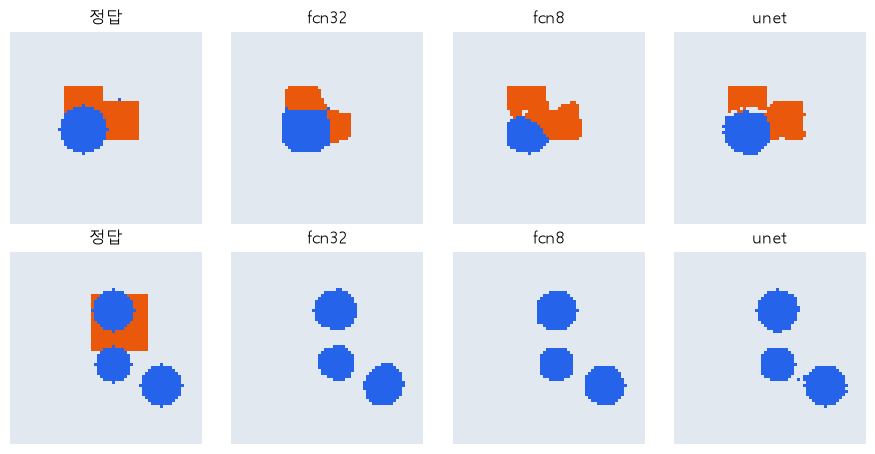

In [21]:
# 4단계: 검증 2장의 정답 · 세 모델 예측
# 왜 · 숫자로 본 차이를 같은 검증 이미지로 눈으로 확인하기 위해
import matplotlib.pyplot as plt               # 그림
from matplotlib.colors import ListedColormap  # 클래스별 고정 색

plt.rcParams["font.family"] = "Malgun Gothic"                            # 한글 제목
cmap = ListedColormap(["#e2e8f0", "#2563eb", "#ea580c"])                 # 배경 · 원 · 사각형
fig, ax = plt.subplots(2, 4, figsize=(9, 4.6))                           # 2장 × (정답 + 모델 3개)
for r, i in enumerate([0, 3]):                                           # 검증 0번 · 3번
    panels = [("정답", Yva[i])] + [(k, results[k][i]) for k in results]  # 4칸
    for c, (title, m) in enumerate(panels):                              # 칸마다
        ax[r, c].imshow(m, cmap=cmap, vmin=0, vmax=2)                    # 번호별 색
        ax[r, c].set_title(title, fontsize=12)                           # 칸 제목
        ax[r, c].axis("off")                                             # 눈금 숨김
plt.tight_layout()                                                       # 간격 정리
plt.show()                                                               # 그림 표시

**결과** · 예측 정답은 경계 정확도 차이가 큼 — mIoU 0.8337 → 0.8718 (0.04), 경계 0.6782 → 0.8325 (0.15)

- `fcn32  | mIoU 0.8337 | 경계 정확도 0.6782` — 1/8 점수를 한 번에 키워 경계가 뭉개짐
- `fcn8   | mIoU 0.8557 | 경계 정확도 0.7787` — 1/4 · 1/2 점수를 더해 경계 +0.10
- `unet   | mIoU 0.8718 | 경계 정확도 0.8325` — 특징을 이어 붙여 한 단계씩 → 경계가 가장 정확
- 그림: FCN-32s는 사각형 모서리가 둥글고 작은 도형이 번짐 · U-Net은 모서리가 각짐 (GPU 실행 값, CPU는 소수 셋째 자리부터 다를 수 있음)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>FCN-32s</td><td>점수를 한 번에 키움 · 가장 단순</td><td>기준선</td></tr>
<tr><td>FCN-8s</td><td>얕은 층 <strong>점수</strong>를 더함 · 채널 수 = 클래스 수라 가벼움</td><td>사전학습 분류 백본을 빠르게 분할로</td></tr>
<tr><td>U-Net</td><td>얕은 층 <strong>특징</strong>을 이어 붙여 디코더가 섞는 법을 학습</td><td>경계 · 작은 구조가 중요한 분할 (기본 선택)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - U-Net은 15 epoch 근처까지 원 · 사각형을 바꿔 칠하다가 30 epoch에서 앞섬
> - epoch를 짧게 잡으면 순위가 뒤집혀 보일 수 있음

> ✅ **한 줄 정리** · 인코더가 같아도 디코더가 고해상도 정보를 얼마나 되살리느냐에 따라 경계 정확도가 크게 달라지며, 특징을 이어 붙이는 U-Net이 가장 정확하다.

**딥러닝 코드에서는**

- 모델 비교는 seed · 데이터 순서 · epoch를 함수 하나(`run`)로 고정하고 바꿀 부분만 인자로
- mIoU와 함께 경계 · 작은 클래스 지표도 보기

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">학습 목표</th><th style="text-align: left;">할 수 있게 된 것</th><th style="text-align: left;">확인 위치</th></tr>
</thead>
<tbody>
<tr><td>1. 분할 종류</td><td>붙은 차 2대: semantic 12픽셀 한 영역 · instance 2개 · panoptic (2, 1) · (2, 2)</td><td>1-1 · 1-2</td></tr>
<tr><td>2. 패치 vs 합성곱</td><td>패치 분류 = 5×5 합성곱 (같은 결과) · 패치 방식은 25배 중복 읽기</td><td>2-1</td></tr>
<tr><td>3. 업샘플링 손계산</td><td>bilinear 22.5 · 전치 합성곱 [3, 8, 5] = Cᵀ 곱 (역연산 아님)</td><td>3-1 ~ 3-3</td></tr>
<tr><td>4. FCN · skip</td><td>Linear = 7×7 Conv · 1/32 → 1/8 격자에서 상자 IoU 0.63 → 0.961</td><td>4-1 ~ 4-4</td></tr>
<tr><td>5. U-Net · Mask R-CNN</td><td>572 → 388 · RoIAlign 13.5 · 마스크 488 · 732픽셀 · 경계 정확도 U-Net 0.8325</td><td>5 · 6 · 7</td></tr>
</tbody></table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td><code>A</code></td><td>분할 종류</td><td>semantic 클래스 · instance 개체 · panoptic 둘 다</td><td>출력 <code>(N, C, H, W)</code> vs 개체 목록</td></tr>
<tr><td><code>A</code></td><td>원-핫</td><td><code>one_hot</code> 뒤 <code>permute</code>로 C를 앞으로</td><td>Dice 손실</td></tr>
<tr><td><code>A</code></td><td>패치 = 합성곱</td><td>같은 분류기를 모든 자리에 한 번에</td><td><code>padding=k // 2</code></td></tr>
<tr><td><code>A</code></td><td>업샘플링</td><td>nearest · unpooling · bilinear · 전치 합성곱</td><td>디코더 선택</td></tr>
<tr><td><code>A</code></td><td>FCN</td><td>FC → 합성곱 · 1×1 점수 · skip 더하기</td><td><code>fcn_resnet50</code></td></tr>
<tr><td><code>A</code></td><td>U-Net</td><td>대칭 · 잘라서 이어 붙이기 · padding 0이면 388</td><td><code>torch.cat(dim=1)</code></td></tr>
<tr><td><code>A</code></td><td>RoIAlign</td><td>반올림 없이 보간</td><td><code>roi_align</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td><code>B</code></td><td>타일 · 거울</td><td>겹치는 타일 · reflect 채움</td><td>큰 사진 추론</td></tr>
<tr><td><code>B</code></td><td>증강 · 가중 손실</td><td>탄성 변형 · 경계 가중 CE</td><td>의료 영상</td></tr>
</tbody></table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

*섹션 → 🎯 질문*

- **1-1** · 붙은 차 두 대를 semantic · instance · panoptic은 어떻게 답하는가?
- **1-2** · 원-핫 라벨의 픽셀마다 합은?
- **2-1** · 패치 분류와 합성곱의 관계는?
- **3-1** · max unpooling은 값을 어디에 놓는가?
- **3-2** · 이중 선형 보간의 계산 순서는?
- **3-3** · 슬라이드의 Deconvolution은 무엇인가?
- **4-1** · FC를 합성곱으로 바꾸면 무엇이 좋아지는가?
- **4-3** · skip이 필요한 이유는?
- **5-1** · 572 입력이 388이 되는 이유는?
- **5-4** · 경계 가중치는 어디에 크게 주는가?
- **6-1** · RoIAlign이 RoIPool보다 나은 점은?
- **7** · 디코더 비교의 결론은?

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**7** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. `torch.tensor([[1., 2.], [3., 4.]])`를 `nearest`로 2배 키운 뒤 1행을 출력
2. 길이 5 입력에 커널 3 · stride 2 · padding 0인 `nn.ConvTranspose1d`의 출력 길이를 출력
3. padding 없는 3×3 합성곱을 두 번 지나면 100이 얼마가 되는지 출력

In [22]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 4-3에서 기둥 폭을 20으로 넓히면 FCN-8s(1/8) 격자에서 기둥 IoU는 0보다 커질까?
2. 5-1에서 입력을 476으로 바꾸면 최종 출력 크기는? (손계산 → 코드)
3. 6-1에서 `output_size=4`로 바꾸면 RoIAlign 왼쪽 위 값은?

In [23]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

*섹션 → 답*

- **1-1** · semantic 한 영역 · instance 마스크 2개 · panoptic (차, 1) · (차, 2)
- **1-2** · 항상 1
- **2-1** · 같은 계산 · 합성곱은 겹치는 계산을 공유
- **3-1** · 풀링 때 기억한 최댓값 자리
- **3-2** · 가로로 두 번 선형 보간 → 세로로 한 번
- **3-3** · 전치 합성곱 (Cᵀ 곱) · 원래 값을 되돌리지 않음
- **4-1** · 입력 크기 자유 · 위치마다 점수 · 사전학습 가중치 재사용
- **4-3** · 점수가 완벽해도 격자보다 가는 물체는 사라짐 → 촘촘한 얕은 층 점수
- **5-1** · padding 0 합성곱이 단계마다 테두리를 깎음
- **5-4** · 붙은 개체 사이 틈
- **6-1** · 좌표 반올림 없이 보간 → 픽셀 정렬
- **7** · 경계 정확도 FCN-32s 0.6782 &lt; FCN-8s 0.7787 &lt; U-Net 0.8325

#### 코드 문제 답

```python
up = F.interpolate(torch.tensor([[[[1., 2.], [3., 4.]]]]), scale_factor=2, mode="nearest")
print(up[0, 0, 0].tolist())  # [1.0, 1.0, 2.0, 2.0]
t = nn.ConvTranspose1d(1, 1, kernel_size=3, stride=2)
print(t(torch.zeros(1, 1, 5)).shape[-1])  # 11
print(100 - 2 - 2)  # 96
```

#### 변형 문제 답

*문제 → 답*

- **1** · 커짐 — 칸(8)보다 넓어져 칸 안 비율이 절반을 넘는 곳이 생김 (직접 실행해 확인)
- **2** · 292 — 476 → 472 → 236 … 바닥 20 → 출력 476 - 184 = 292
- **3** · 9.5 — 칸 하나 크기 1 · 첫 칸 가운데 (1, 1) → 8 × 1 + 1 = 9, 보간점 (1.0, 1.0)은 sampling_ratio 1이면 9.0 (직접 확인)

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">틀린 내용</th><th style="text-align: left;">틀린 이유</th><th style="text-align: left;">올바른 원칙</th><th style="text-align: left;">재발 방지 질문</th></tr>
</thead>
<tbody>
<tr><td>(예) Deconvolution = 합성곱을 되돌리는 연산이라고 답함</td><td>이름만 보고 판단</td><td>전치 합성곱은 Cᵀ 곱 · 크기만 키움</td><td>결과가 원래 값과 같은지 계산해 봤나?</td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
</tbody></table>

---
## 면접 30초 답변

**Q1. Semantic Segmentation과 Instance Segmentation의 차이는?**
> - Semantic은 모든 픽셀에 클래스를 붙이지만 같은 클래스 개체를 구분하지 않습니다.
> - Instance는 개체마다 마스크를 따로 내서 같은 클래스도 하나씩 구분합니다.
> - 둘을 합쳐 모든 픽셀에 클래스와 개체 번호를 주는 것이 Panoptic입니다.

**Q2. FCN은 분류 CNN을 어떻게 분할 모델로 바꾸나요?**
> - 완전 연결층을 같은 가중치의 합성곱으로 바꿔 입력 크기 제약을 없애고 위치마다 클래스 점수 지도를 만듭니다.
> - 줄어든 점수 지도는 업샘플링으로 입력 크기로 키우고, 얕은 층의 점수를 더하는 skip으로 경계를 보완합니다.

**Q3. U-Net이 FCN보다 경계를 잘 맞히는 이유는?**
> - 인코더와 디코더를 대칭으로 두고 같은 단계의 고해상도 특징을 디코더에 이어 붙여, 디코더가 위치 정보와 문맥을 함께 쓰도록 학습하기 때문입니다.
> - 제 실험에서도 같은 인코더로 경계 정확도가 FCN-8s 0.78, U-Net 0.83이었습니다.

**Q4. RoIAlign은 왜 필요한가요?**
> - RoIPool은 박스 좌표를 특징 맵 칸에 맞춰 반올림해 마스크가 몇 픽셀씩 어긋납니다.
> - RoIAlign은 반올림 없이 소수 위치의 값을 bilinear로 보간해 읽어 마스크 정렬이 정확해집니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>F.one_hot</code> · <code>permute</code></td><td>torch</td><td>정수 라벨 → 원-핫 (C, H, W)</td><td>1-2 <code>F.one_hot(label, num_classes=3)</code></td></tr>
<tr><td><code>F.unfold</code></td><td>torch.nn.functional</td><td>픽셀마다 패치 자르기</td><td>2-1 <code>F.unfold(img, kernel_size=5, padding=2)</code></td></tr>
<tr><td><code>nn.MaxPool2d(return_indices=True)</code> · <code>nn.MaxUnpool2d</code></td><td>torch.nn</td><td>최댓값 자리 기억 · 되돌리기</td><td>3-1 <code>unpool(pooled, where)</code></td></tr>
<tr><td><code>F.interpolate(mode="bilinear")</code></td><td>torch.nn.functional</td><td>이중 선형 보간</td><td>3-2 <code>F.interpolate(grid, size=(5, 5), …)</code></td></tr>
<tr><td><code>F.conv_transpose1d</code> · <code>nn.ConvTranspose2d</code></td><td>torch</td><td>전치 합성곱</td><td>3-3 <code>F.conv_transpose1d(y1, k)</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>nn.Conv2d(kernel_size=7)</code> · <code>kernel_size=1</code></td><td>torch.nn</td><td>FC → 합성곱 · 점수 머리</td><td>4-1 <code>conv7(big)</code> · 4-2 <code>nn.Conv2d(512, 21, 1)</code></td></tr>
<tr><td><code>F.avg_pool2d</code></td><td>torch.nn.functional</td><td>격자 칸 안 비율</td><td>4-3 <code>F.avg_pool2d(onehot, stride)</code></td></tr>
<tr><td><code>F.cross_entropy(reduction="none")</code></td><td>torch.nn.functional</td><td>픽셀 손실 지도</td><td>5-4 <code>F.cross_entropy(logits, target, reduction="none")</code></td></tr>
<tr><td><code>F.pad(mode="reflect")</code></td><td>torch.nn.functional</td><td>거울 채우기</td><td>5-2 <code>F.pad(tile, (2, 2, 2, 2), mode="reflect")</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>v2.ElasticTransform</code></td><td>torchvision.transforms.v2</td><td>탄성 변형</td><td>5-3 <code>elastic(tv_tensors.Image(img), tv_tensors.Mask(mask))</code></td></tr>
<tr><td><code>roi_pool</code> · <code>roi_align</code></td><td>torchvision.ops</td><td>박스 특징 자르기</td><td>6-1 <code>roi_align(fmap, box, output_size=2, …)</code></td></tr>
<tr><td><code>binary_cross_entropy_with_logits</code></td><td>torch.nn.functional</td><td>마스크 이진 CE</td><td>6-2 <code>F.binary_cross_entropy_with_logits(…)</code></td></tr>
</tbody></table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">✅ 할 것</th><th style="text-align: left;">⚠️ 하지 말 것</th></tr>
</thead>
<tbody>
<tr><td>업샘플링 방법을 목적에 맞게 고름</td><td>마스크를 bilinear로 키우기</td></tr>
<tr><td>FC는 같은 가중치의 합성곱으로</td><td>분류 모델에 큰 사진을 그대로 넣기</td></tr>
<tr><td>skip으로 고해상도 정보 전달</td><td>1/32 점수를 한 번에 키우고 경계를 기대</td></tr>
<tr><td>padding 0이면 crop, 1이면 크기 맞추기</td><td>크기 확인 없이 <code>torch.cat</code></td></tr>
<tr><td>RoIAlign으로 박스 특징 자르기</td><td>Deconvolution을 역연산으로 설명</td></tr>
</tbody></table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">짝</th><th style="text-align: left;">차이</th><th style="text-align: left;">결론</th></tr>
</thead>
<tbody>
<tr><td>semantic vs instance vs panoptic</td><td>클래스 지도 vs 개체 마스크 vs (클래스, 번호)</td><td>필요한 답으로 고름</td></tr>
<tr><td>패치 분류 vs 합성곱</td><td>자리마다 다시 계산 vs 한 번에 공유</td><td>합성곱 (FCN)</td></tr>
<tr><td>nearest vs bilinear</td><td>복사 vs 가중 평균</td><td>마스크는 nearest</td></tr>
<tr><td>max unpooling vs 전치 합성곱</td><td>기억한 자리 vs 학습한 도장</td><td>대칭 구조 vs 일반 디코더</td></tr>
<tr><td>FCN skip vs U-Net skip</td><td>점수 더하기 vs 특징 이어 붙이기</td><td>경계는 U-Net</td></tr>
<tr><td>RoIPool vs RoIAlign</td><td>반올림 · 최댓값 vs 보간</td><td>마스크는 RoIAlign</td></tr>
</tbody></table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">언제</th><th style="text-align: left;">할 일</th><th style="text-align: left;">걸리는 시간</th></tr>
</thead>
<tbody>
<tr><td>내일</td><td>기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td><td>15분</td></tr>
<tr><td>3일 뒤</td><td>변형 문제 3개 · 3-2 이중 선형 보간과 5-1 크기 변화를 손으로 다시</td><td>20분</td></tr>
<tr><td>7일 뒤</td><td>7장 세 디코더를 빈 셀에 다시 짜서 결과 비교</td><td>30분</td></tr>
<tr><td>14일 뒤</td><td>오답 노트에 남은 문제만 · 파일별 2(Day02) 전에 4 · 5 · 6장 ✅ 줄만 읽기</td><td>15분</td></tr>
</tbody></table>

---
## 부록

### 이 노트북을 만든 방법

- 원본 PDF 62쪽을 3단원(Segmentation · Semantic · Instance) 순서 그대로 1 ~ 6장 · 14개 섹션으로 나눔
- 원본은 개념 슬라이드라 실행 코드가 없음 → 모든 코드는 보강 (작은 텐서로 슬라이드 내용을 직접 계산)
- 수식 · 구조 그림만 있는 쪽은 장 그림과 손계산 코드로 옮김 · 7장 종합 실습은 새로 추가

- - 원본 표기 정정 (PDF 쪽): 'Segmentaton'(45쪽)
- Segmentation
- 'Rol'(55 · 56쪽) · RoI
- '아키텍쳐'(32 · 33쪽) · 아키텍처
- 'Path 탐색'(38쪽) · Patch

- - 원본 내용 정정: 'Deconvolution'은 역연산이 아닌 전치 합성곱 (3-3)
- FC를 '제거'가 아닌 '합성곱으로 변환' (4-1)
- U-Net '실시간'은 512×512 한 장 1초 이내 수준

### 읽는 법

*표시 → 의미*

- **`A` · `B`** · **A** 딥러닝 코드에 바로 나오는 필수 · **B** 알아두면 되는 것
- **🎯** · 이번 섹션에서 답해야 할 질문
- **💡** · 쉬운 설명 · 비유
- **⚠️** · 자주 하는 실수
- **✅** · 기억할 결론 = 🎯 질문의 답

- **섹션 앞부분** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드
- **섹션 뒷부분** · 결과(예측 정답 · 출력 줄) → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리
- **코드 주석** · 코드 위는 이 단계에서 하는 일, 코드 옆은 그 줄이 필요한 이유 (줄마다 · 열 맞춤)

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">내용</th><th style="text-align: left;">이 노트북</th></tr>
</thead>
<tbody>
<tr><td>3 ~ 5쪽</td><td>Segmentation 정의 · 세 종류 · one-hot 라벨</td><td>1-1 · 1-2</td></tr>
<tr><td>7 ~ 9쪽</td><td>픽셀 · 패치 분류 · 다운샘플링을 없앤다면</td><td>2-1</td></tr>
<tr><td>10 · 11쪽</td><td>다운 · 업샘플링 · nearest · bed of nails · max unpooling</td><td>3-1</td></tr>
<tr><td>12 ~ 15쪽</td><td>bilinear · 선형 · 이중 선형 보간 · deconvolution</td><td>3-2 · 3-3</td></tr>
<tr><td>16 ~ 25쪽</td><td>FCN: FC 제거(→ 합성곱) · 1×1 heat map · 업샘플링</td><td>4-1 · 4-2</td></tr>
<tr><td>22 ~ 28쪽</td><td>skip · FCN-8s · 손실 · 장단점</td><td>4-3 · 4-4</td></tr>
<tr><td>29 ~ 36쪽</td><td>U-Net 구조 · contracting / expansive path</td><td>5-1</td></tr>
<tr><td>37 · 38쪽</td><td>overlap-tile · mirroring</td><td>5-2</td></tr>
<tr><td>39 ~ 42쪽</td><td>증강 (elastic) · 경계 가중 손실 · 장단점</td><td>5-3 · 5-4</td></tr>
<tr><td>43 ~ 49 · 54쪽</td><td>semantic vs instance · Mask R-CNN 구조 · 손실</td><td>6-2</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">내용</th><th style="text-align: left;">이 노트북</th></tr>
</thead>
<tbody>
<tr><td>55 ~ 59쪽</td><td>RoIPool · RoIAlign</td><td>6-1</td></tr>
<tr><td>60 ~ 62쪽</td><td>후처리 · 최종 출력</td><td>6-2</td></tr>
<tr><td>(새로 추가)</td><td>디코더 3종 비교</td><td>7. 종합 실습</td></tr>
</tbody></table>

### 전체 코드

1 ~ 7장 코드를 장별 셀로 모음. **위에서부터 이 셀들만 실행해도 전체가 동작**하며, 각 블록 머리 주석의 번호가 섹션.

**실행 흐름**

1. 0. 준비: 도구 · seed · 장치

In [24]:
# ---------- 0. 준비 ----------
# 실행 환경: 모든 코드는 보강 (원본 PDF에는 실행 코드가 없음)
# 왜 · PDF 설명을 직접 실행해 확인할 수 있게 도구 · seed · 장치를 한곳에서 정하기 위해
import os      # 환경 변수
import random  # 파이썬 난수

# 왜 · torch와 numpy를 한 커널에서 쓸 때 커널이 멈추는 충돌을 막기 위해
if "KMP_DUPLICATE_LIB_OK" not in os.environ:           # Windows Anaconda 충돌 방지
    os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"        # numpy · torch OpenMP 중복 허용
if "CUBLAS_WORKSPACE_CONFIG" not in os.environ:        # 같은 GPU · 같은 버전에서 행렬 곱도 같은 값
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # 결정적 cuBLAS 작업 공간

import numpy as np               # 배열 · 도형 그리기
import torch                     # 텐서 · 모델
import torch.nn.functional as F  # 보간 · 손실 함수
import torchvision               # roi_align · v2 증강
from torch import nn             # 층 만들기

# 왜 · python · numpy · torch 난수를 한 기준값으로 고정하기 위해
SEED = 42                                                              # 난수 기준값
random.seed(SEED)                                                      # 파이썬 random 고정
np.random.seed(SEED)                                                   # numpy 고정
torch.manual_seed(SEED)                                                # torch 고정 (CPU · GPU)
torch.backends.cudnn.deterministic = True                              # 같은 GPU · 같은 버전에서 합성곱도 같은 값
torch.backends.cudnn.benchmark = False                                 # 계산 방법이 바뀌지 않게
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU 있으면 GPU
print("torch", torch.__version__.split("+")[0], "· torchvision",       # 버전 기록
      torchvision.__version__.split("+")[0], "· device:", device.type)

torch 2.11.0 · torchvision 0.26.0 · device: cuda


**실행 흐름**

1. 1-1 세 가지 분할 정답
2. 1-2 원-핫 라벨

In [25]:
# ---------- 1-1 ----------
# 같은 장면(6×8)을 세 가지 분할 정답으로 나타내기 (0 하늘 · 1 도로 · 2 차)
# 왜 · 세 분할 방식의 정답 형식 차이를 같은 장면으로 비교하기 위해
sem = torch.zeros(6, 8, dtype=torch.long)  # 의미 분할 지도
sem[3:, :] = 1                             # 아래 세 줄 = 도로
sem[2:5, 1:3] = 2                          # 차 A
sem[2:5, 3:5] = 2                          # 차 B (A와 붙어 있음)
print(sem)                                 # 픽셀마다 클래스 번호


# 인스턴스: 셀 수 있는 것(차)만 개체마다 마스크 한 장
# 왜 · 인스턴스 분할은 셀 수 있는 개체만 따로 나눈다는 것을 보이기 위해
car_a = torch.zeros(6, 8, dtype=torch.bool)              # 차 A 마스크
car_a[2:5, 1:3] = True                                   # A 자리
car_b = torch.zeros(6, 8, dtype=torch.bool)              # 차 B 마스크
car_b[2:5, 3:5] = True                                   # B 자리
instances = [("car", car_a), ("car", car_b)]             # (클래스, 마스크) 목록
print("의미 분할로 본 차 픽셀:", int((sem == 2).sum()),  # 두 대가 한 영역
      "| 인스턴스 개수:", len(instances))                # 개체 2개


# 파노픽: 모든 픽셀에 (클래스, 개체 번호) · 하늘 · 도로는 번호 0
# 왜 · 파노픽은 모든 픽셀에 클래스와 개체 번호를 함께 준다는 것을 보이기 위해
pan_id = torch.zeros(6, 8, dtype=torch.long)                                 # 개체 번호 지도
for k, (_, m) in enumerate(instances, start=1):                              # 차마다
    pan_id[m] = k                                                            # 1번 · 2번
pairs = sorted(set(zip(sem.flatten().tolist(), pan_id.flatten().tolist())))  # 나온 쌍
print("파노픽 (클래스, 개체) 쌍:", pairs)                                    # 모든 픽셀에 하나씩


# ---------- 1-2 ----------
# 정수 라벨 지도 → 클래스별 0/1 지도 (원-핫)
# 왜 · 원-핫으로 바꾸고 되돌려 두 표현이 같은 정보라는 것을 확인하기 위해
label = torch.tensor([[0, 0, 1, 1],                            # 0 배경 · 1 사람 · 2 자전거
                      [0, 1, 1, 2],
                      [0, 0, 2, 2],
                      [0, 0, 0, 2]])
onehot = F.one_hot(label, num_classes=3)                       # (H, W, C)
onehot = onehot.permute(2, 0, 1)                               # → (C, H, W) 모델 출력과 같은 순서
print("label:", tuple(label.shape), "→ one-hot:", tuple(onehot.shape))  # 모양 변화
print("사람(1) 지도:\n", onehot[1])                            # 사람 자리만 1
print("픽셀마다 합:", onehot.sum(0).unique().tolist())         # 정답은 한 픽셀에 하나
print("되돌리기 같음:", torch.equal(onehot.argmax(0), label))  # argmax → 다시 번호

tensor([[0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0],
        [0, 2, 2, 2, 2, 0, 0, 0],
        [1, 2, 2, 2, 2, 1, 1, 1],
        [1, 2, 2, 2, 2, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1]])
의미 분할로 본 차 픽셀: 12 | 인스턴스 개수: 2
파노픽 (클래스, 개체) 쌍: [(0, 0), (1, 0), (2, 1), (2, 2)]
label: (4, 4) → one-hot: (3, 4, 4)
사람(1) 지도:
 tensor([[0, 0, 1, 1],
        [0, 1, 1, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0]])
픽셀마다 합: [1]
되돌리기 같음: True


**실행 흐름**

1. 2-1 패치 분류 = 합성곱 · 중복 읽기

In [26]:
# ---------- 2-1 ----------
# 픽셀마다 5×5 패치를 잘라 분류 vs 합성곱 한 번 (같은 가중치)
# 왜 · 패치 분류와 합성곱이 같은 계산이라는 것을 직접 확인하기 위해
img = torch.randn(1, 3, 16, 16)                                              # 16×16 사진 1장
patches = F.unfold(img, kernel_size=5, padding=2)                            # 픽셀마다 5×5×3 조각
print("패치 수:", patches.shape[-1], "· 패치 하나 길이:", patches.shape[1])  # 256개 · 75


# 패치마다 같은 Linear(75 → 클래스 4)로 분류
# 왜 · PDF의 패치 분류 방식을 그대로 구현하기 위해
fc = nn.Linear(3 * 5 * 5, 4)                               # 패치 → 클래스 점수
by_patch = fc(patches.transpose(1, 2))                     # (1, 256, 4) · 256번 분류
by_patch = by_patch.transpose(1, 2).reshape(1, 4, 16, 16)  # 픽셀 자리로 다시


# 같은 가중치를 5×5 합성곱으로 옮기면 한 번에
# 왜 · 같은 가중치로 합성곱 결과가 일치하는지 대조하기 위해
conv = nn.Conv2d(3, 4, kernel_size=5, padding=2)                   # 패치 분류 = 합성곱
with torch.no_grad():                                              # 가중치 복사는 학습이 아님
    conv.weight.copy_(fc.weight.view(4, 3, 5, 5))                  # 같은 숫자를 창 모양으로
    conv.bias.copy_(fc.bias)                                       # 편향도 그대로
    by_conv = conv(img)                                            # 합성곱 1번
print("결과 같음:", torch.allclose(by_patch, by_conv, atol=1e-5))  # 계산이 같은가


# 겹치는 계산량: 패치 방식은 이웃 패치와 같은 픽셀을 다시 읽음
# 왜 · 패치 방식이 왜 비효율적인지 중복 읽기 횟수로 보이기 위해
reads = patches.shape[-1] * patches.shape[1]                   # 패치 방식으로 읽는 값 수
print("패치 방식 읽는 값:", reads, "· 원본 값:", img.numel(),  # 몇 배 중복?
      "· 중복 배수:", reads // img.numel())

패치 수: 256 · 패치 하나 길이: 75
결과 같음: True
패치 방식 읽는 값: 19200 · 원본 값: 768 · 중복 배수: 25


**실행 흐름**

1. 3-1 값을 놓는 업샘플링
2. 3-2 선형 · 이중 선형 보간
3. 3-3 1차원 · 행렬로 본 전치 합성곱

In [27]:
# ---------- 3-1 ----------
# 2×2 → 4×4 키우기 세 가지: 가장 가까운 값 · 못 박기 · 최댓값 자리 되돌리기
# 왜 · 값을 놓는 업샘플링 방법마다 결과가 어떻게 다른지 비교하기 위해
small = torch.tensor([[[[1.0, 2.0], [3.0, 4.0]]]])           # (1, 1, 2, 2)
near = F.interpolate(small, scale_factor=2, mode="nearest")  # 칸 복사
nails = torch.zeros(1, 1, 4, 4)                              # 큰 판을 0으로
nails[..., ::2, ::2] = small                                 # 왼쪽 위 칸에만 값 (Bed of Nails)
print("nearest:\n", near[0, 0])                              # 2×2 블록 복사
print("bed of nails:\n", nails[0, 0])                        # 나머지는 0


# Max Unpooling: 줄일 때 기억한 최댓값 자리로 되돌림
# 왜 · 풀링 때 위치를 기억해야 되돌릴 수 있다는 것을 보이기 위해
x4 = torch.tensor([[[[1.0, 5.0, 2.0, 1.0],              # 4×4 특징 지도
                     [3.0, 2.0, 7.0, 4.0],
                     [6.0, 1.0, 1.0, 2.0],
                     [2.0, 0.0, 3.0, 8.0]]]])
pool = nn.MaxPool2d(2, return_indices=True)             # 최댓값 + 자리
unpool = nn.MaxUnpool2d(2)                              # 기억한 자리로 되돌리기
pooled, where = pool(x4)                                # 2×2로 줄임
print("pooled:", pooled.flatten().tolist(), "· 자리:", where.flatten().tolist())  # 최댓값 · 위치
print("max unpooling:\n", unpool(pooled, where)[0, 0])  # 최댓값 자리만 채움


# ---------- 3-2 ----------
# 선형 보간: 두 점 (x0, y0) · (x1, y1) 사이 x의 값
# 왜 · 이중 선형 보간의 기본인 1차원 보간을 손으로 계산하기 위해
def linear(x, x0, y0, x1, y1):                    # 직선의 방정식
    return y0 + (y1 - y0) * (x - x0) / (x1 - x0)  # 기울기 × 이동 거리


print("x = 2.5 →", linear(2.5, 2, 10, 4, 20))  # 10과 20 사이 1/4 지점


# 이중 선형: 가로로 두 번 → 세로로 한 번 (네 점의 가중 평균)
# 왜 · PDF의 이중 선형 계산 순서를 숫자로 따라가기 위해
q = {(0, 0): 10.0, (1, 0): 20.0, (0, 1): 30.0, (1, 1): 40.0}      # (x, y): 값
x, y = 0.25, 0.5                                                  # 구할 위치
top = linear(x, 0, q[(0, 0)], 1, q[(1, 0)])                       # 위쪽 가로 보간
bottom = linear(x, 0, q[(0, 1)], 1, q[(1, 1)])                    # 아래쪽 가로 보간
print("손계산:", top, bottom, "→", linear(y, 0, top, 1, bottom))  # 세로 보간


# PyTorch로 확인: 2×2를 5×5로 키우면 (0.25, 0.5) 자리가 같은 값
# 왜 · 손계산이 F.interpolate 결과와 같은지 확인하기 위해
grid = torch.tensor([[[[10.0, 20.0], [30.0, 40.0]]]])         # 위 줄 10 · 20, 아래 줄 30 · 40
big = F.interpolate(grid, size=(5, 5), mode="bilinear", align_corners=True)  # 끝을 맞춰 키움
print("F.interpolate (행 2, 열 1):", big[0, 0, 2, 1].item())  # y 0.5 · x 0.25 자리


# ---------- 3-3 ----------
# 1차원으로 본 합성곱 vs 전치 합성곱: [1, 2, 3]과 커널 [1, 1]
# 왜 · 전치 합성곱이 크기를 키우는 원리를 가장 작은 예로 보기 위해
x1 = torch.tensor([[[1.0, 2.0, 3.0]]])                                         # (배치, 채널, 길이)
k = torch.tensor([[[1.0, 1.0]]])                                               # 커널 2칸
print("합성곱:", F.conv1d(x1, k).flatten().tolist())                           # 3칸 → 2칸
y1 = F.conv1d(x1, k)                                                           # 합성곱 결과 [3, 5]
print("그 결과를 전치 합성곱:", F.conv_transpose1d(y1, k).flatten().tolist())  # 2칸 → 3칸


# 행렬로 보면: 합성곱 = C 곱하기, 전치 합성곱 = Cᵀ 곱하기 (역행렬이 아님)
# 왜 · 전치 합성곱이 역연산이 아니라는 것을 행렬로 확인하기 위해
C = torch.tensor([[1.0, 1.0, 0.0],                         # 커널을 한 칸씩 민 행렬
                  [0.0, 1.0, 1.0]])
print("C @ x:", (C @ x1.flatten()).tolist(), "· Cᵀ @ y:",  # 위 두 결과와 같음
      (C.T @ y1.flatten()).tolist())

nearest:
 tensor([[1., 1., 2., 2.],
        [1., 1., 2., 2.],
        [3., 3., 4., 4.],
        [3., 3., 4., 4.]])
bed of nails:
 tensor([[1., 0., 2., 0.],
        [0., 0., 0., 0.],
        [3., 0., 4., 0.],
        [0., 0., 0., 0.]])
pooled: [5.0, 7.0, 6.0, 8.0] · 자리: [1, 6, 8, 15]
max unpooling:
 tensor([[0., 5., 0., 0.],
        [0., 0., 7., 0.],
        [6., 0., 0., 0.],
        [0., 0., 0., 8.]])
x = 2.5 → 12.5
손계산: 12.5 32.5 → 22.5
F.interpolate (행 2, 열 1): 22.5
합성곱: [3.0, 5.0]
그 결과를 전치 합성곱: [3.0, 8.0, 5.0]
C @ x: [3.0, 5.0] · Cᵀ @ y: [3.0, 8.0, 5.0]


**실행 흐름**

1. 3-3 2D 전치 합성곱 · 파라미터 수

In [28]:
# 2D 전치 합성곱으로 2배 키우기: 커널도 학습하는 파라미터
# 왜 · 보간과 달리 전치 합성곱은 학습할 값이 있다는 것을 보이기 위해
up = nn.ConvTranspose2d(8, 8, kernel_size=2, stride=2)                    # 크기 2배
feat = torch.randn(1, 8, 7, 7)                                            # 7×7 특징 지도
print("ConvTranspose2d:", tuple(feat.shape), "→", tuple(up(feat).shape),  # 7 → 14
      "· 학습 파라미터", sum(p.numel() for p in up.parameters()))

ConvTranspose2d: (1, 8, 7, 7) → (1, 8, 14, 14) · 학습 파라미터 264


**실행 흐름**

1. 4-1 완전 연결층 → 합성곱
2. 4-2 1×1 합성곱 · 업샘플링
3. 4-3 FCN-32s · 16s · 8s IoU 상한

In [29]:
# ---------- 4-1 ----------
# 분류 CNN의 마지막 완전 연결층(펼친 7×7) = 7×7 합성곱 (같은 가중치)
# 왜 · FCN이 완전 연결층을 합성곱으로 바꾸는 근거를 직접 확인하기 위해
fc = nn.Linear(16 * 7 * 7, 10)                        # 펼친 특징 → 10클래스
conv7 = nn.Conv2d(16, 10, kernel_size=7)              # 같은 일을 합성곱으로
with torch.no_grad():                                 # 가중치 옮기기
    conv7.weight.copy_(fc.weight.view(10, 16, 7, 7))  # 줄 → 창 모양
    conv7.bias.copy_(fc.bias)                         # 편향 그대로
feat = torch.randn(1, 16, 7, 7)                       # 학습 때 크기의 특징
same = torch.allclose(fc(feat.flatten(1)), conv7(feat).flatten(1), atol=1e-5)  # 결과 비교
print("7×7 입력 · Linear = Conv:", same)              # 같은 계산


# 더 큰 입력: Linear는 길이가 안 맞아 에러, 합성곱은 점수 지도
# 왜 · 합성곱으로 바꾸면 입력 크기 제약이 없어진다는 것을 보이기 위해
big = torch.randn(1, 16, 14, 14)                                     # 두 배 큰 사진의 특징
try:
    fc(big.flatten(1))                                               # 펼친 길이 3136 ≠ 784
except RuntimeError as e:                                            # 길이가 안 맞으면 여기로
    print("Linear:", type(e).__name__)                               # 크기 고정
print("Conv:", tuple(conv7(big).shape), "← 위치마다 10클래스 점수")  # 8×8 지도


# ---------- 4-2 ----------
# FCN 끝부분: 1×1 합성곱으로 채널 = 클래스 수 → 입력 크기로 키우기
# 왜 · FCN 출력이 입력과 같은 크기의 점수 지도가 되는 과정을 보기 위해
feat = torch.randn(1, 512, 7, 7)  # 224 입력이 1/32로 줄어든 특징
score = nn.Conv2d(512, 21, kernel_size=1)(feat)  # 위치마다 21클래스 점수 (heat map)
print("1×1 합성곱:", tuple(feat.shape), "→", tuple(score.shape))                  # 채널만 바뀜
up = F.interpolate(score, size=(224, 224), mode="bilinear", align_corners=False)  # 32배
print("업샘플링:", tuple(up.shape), "· 예측 지도:", tuple(up.argmax(1).shape))    # 입력 크기


# 1×1 합성곱 = 픽셀마다 같은 Linear (채널 축만 섞음)
# 왜 · 1×1 합성곱의 뜻을 가중치 비교로 확인하기 위해
w = torch.randn(3, 4)                            # 4채널 → 3클래스
x = torch.randn(1, 4, 2, 2)                      # 2×2 특징
by_einsum = torch.einsum("oc,nchw->nohw", w, x)  # 픽셀마다 행렬 곱
by_conv = F.conv2d(x, w.view(3, 4, 1, 1))        # 1×1 합성곱
print("1×1 Conv = 픽셀별 Linear:", torch.allclose(by_einsum, by_conv, atol=1e-6))  # 같음


# ---------- 4-3 ----------
# 완벽한 점수를 줘도 격자가 거칠면 가는 물체가 사라짐 (FCN-32s · 16s · 8s)
# 왜 · skip 연결 없이 크게 키우면 얻을 수 있는 IoU에 상한이 있다는 것을 보이기 위해
H = W = 224                                     # 입력 크기
truth = torch.zeros(1, H, W, dtype=torch.long)  # 정답: 배경 0
truth[:, 40:180, 100:107] = 1                   # 폭 7픽셀 기둥
truth[:, 120:200, 150:210] = 2                  # 큰 상자


# 왜 · 격자 크기마다 얻을 수 있는 최고 IoU를 계산하기 위해
def best_iou(stride):  # 격자 칸마다 정확한 클래스 비율을 점수로 준 상한
    onehot = F.one_hot(truth, 3).permute(0, 3, 1, 2).float()              # (1, 3, H, W)
    coarse = F.avg_pool2d(onehot, stride)                                 # 칸 안 비율 = 완벽한 점수
    pred = F.interpolate(coarse, size=(H, W), mode="bilinear").argmax(1)  # 키워서 고름
    inter = [((pred == c) & (truth == c)).sum().item() for c in (1, 2)]   # 클래스별 교집합
    union = [((pred == c) | (truth == c)).sum().item() for c in (1, 2)]   # 합집합
    return [round(i / u, 3) for i, u in zip(inter, union)]                # 기둥 · 상자 IoU


for name, s in [("FCN-32s", 32), ("FCN-16s", 16), ("FCN-8s", 8), ("1/4 격자", 4)]:  # 격자만 다름
    print(f"{name} (1/{s}) · 기둥 IoU, 상자 IoU =", best_iou(s))                    # 상한

7×7 입력 · Linear = Conv: True
Linear: RuntimeError
Conv: (1, 10, 8, 8) ← 위치마다 10클래스 점수
1×1 합성곱: (1, 512, 7, 7) → (1, 21, 7, 7)
업샘플링: (1, 21, 224, 224) · 예측 지도: (1, 224, 224)
1×1 Conv = 픽셀별 Linear: True
FCN-32s (1/32) · 기둥 IoU, 상자 IoU = [0.0, 0.63]
FCN-16s (1/16) · 기둥 IoU, 상자 IoU = [0.0, 0.915]
FCN-8s (1/8) · 기둥 IoU, 상자 IoU = [0.0, 0.961]
1/4 격자 (1/4) · 기둥 IoU, 상자 IoU = [0.994, 0.998]


**실행 흐름**

1. 4-4 픽셀 CE 손계산 · 대조

In [30]:
# ---------- 4-4 ----------
# 픽셀 단위 CE: 픽셀마다 softmax → 정답 확률의 -log → 평균
# 왜 · 픽셀 CE를 손으로 계산해 F.cross_entropy와 맞춰 보기 위해
logits = torch.tensor([[[[3.0, 0.0]],                         # 클래스 0 점수 (1×2 사진)
                        [[0.0, 0.0]],                         # 클래스 1
                        [[0.0, 3.0]]]])                       # 클래스 2
target = torch.tensor([[[0, 1]]])                             # 왼쪽 정답 0 · 오른쪽 정답 1
prob = logits.softmax(dim=1)                                  # 픽셀마다 확률 합 1
p_true = prob.gather(1, target[:, None]).flatten()            # 정답 클래스 확률
print("정답 확률:", [round(p, 4) for p in p_true.tolist()])   # 맞힘 · 틀림
print("손으로 평균:", round(-p_true.log().mean().item(), 4),  # 픽셀 손실 평균
      "· F.cross_entropy:", round(F.cross_entropy(logits, target).item(), 4))  # 같은 값

정답 확률: [0.9094, 0.0453]
손으로 평균: 1.5949 · F.cross_entropy: 1.5949


**실행 흐름**

1. 5-1 원 논문 크기 변화
2. 5-2 거울 채우기 · 타일 수

In [31]:
from torchvision import tv_tensors     # 사진 · 마스크 표시
from torchvision.transforms import v2  # 같이 바꾸는 증강
from scipy import ndimage              # 거리 계산


# ---------- 5-1 ----------
# 원 논문 U-Net: padding 없는 3×3 합성곱 → 크기가 매번 2씩 줄어듦
# 왜 · 원 논문의 572 → 388 크기 변화를 직접 재현하기 위해
def conv2(c_in, c_out):                                          # 3×3 합성곱 2번 (padding 0)
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3), nn.ReLU(),   # 크기 -2
                         nn.Conv2d(c_out, c_out, 3), nn.ReLU())  # 크기 -2


# 왜 · 크기가 다른 인코더 특징을 가운데만 잘라 이어 붙이기 위해
def crop(enc, size):                         # 인코더 특징의 가운데를 디코더 크기로 자름
    d = (enc.shape[-1] - size) // 2          # 양쪽에서 자를 칸
    return enc[..., d:d + size, d:d + size]  # 가운데


# 왜 · 층마다 크기를 찍어 논문 그림과 비교하기 위해
ch = [4, 8, 16, 32, 64]  # 원 논문 64 ~ 1024 채널 대신 작게 (크기 계산은 같음)
x = torch.randn(1, 1, 572, 572)                                          # 원 논문 입력 572×572
skips, sizes = [], [x.shape[-1]]                                         # skip 모음 · 크기 기록
for i in range(4):                                                       # 내려가기 4번
    x = conv2(x.shape[1], ch[i])(x)                                      # 크기 -4
    skips.append(x)                                                      # 자르기 전 특징
    sizes.append(x.shape[-1])                                            # 합성곱 뒤 크기
    x = F.max_pool2d(x, 2)                                               # 크기 ½
x = conv2(x.shape[1], ch[4])(x)                                          # 바닥
sizes.append(x.shape[-1])                                                # 바닥 크기
for s in reversed(skips):                                                # 올라가기 4번
    x = nn.ConvTranspose2d(x.shape[1], x.shape[1] // 2, 2, stride=2)(x)  # 크기 2배
    x = torch.cat([crop(s, x.shape[-1]), x], dim=1)                      # 잘라서 이어 붙이기
    x = conv2(x.shape[1], x.shape[1] // 2)(x)                            # 크기 -4
    sizes.append(x.shape[-1])                                            # 단계 크기
print("크기 변화:", sizes)                                               # 572 → … → 388
print("출력:", tuple(nn.Conv2d(x.shape[1], 2, 1)(x).shape))              # 1×1로 2클래스


# ---------- 5-2 ----------
# 타일 가장자리 문맥 채우기: 0으로 채우기 vs 거울처럼 비추기
# 왜 · 가장자리를 거울처럼 채우는 이유를 값으로 비교하기 위해
tile = torch.arange(1.0, 10.0).view(1, 1, 3, 3)             # 3×3 타일
zero = F.pad(tile, (2, 2, 2, 2), mode="constant", value=0)  # 바깥 0
mirror = F.pad(tile, (2, 2, 2, 2), mode="reflect")          # 바깥 = 안쪽을 거울로
print("zero padding 1행:", zero[0, 0, 2].tolist())          # 가운데 줄
print("mirroring 1행:", mirror[0, 0, 2].tolist())           # 실제와 비슷한 값


# 큰 사진을 겹치는 타일로: 출력 388 칸마다 입력 572 (사방 92 여유)
# 왜 · 큰 사진을 몇 장의 타일로 나눠야 하는지 계산하기 위해
side = 1024          # 사진 한 변
n = -(-side // 388)  # 필요한 타일 수 (올림)
print(f"1024×1024 사진 → 타일 {n}×{n} = {n * n}장 · 타일 입력 572 = 388 + 2 × 92")  # 겹침

크기 변화:

 [572, 568, 280, 136, 64, 28, 52, 100, 196, 388]
출력: (1, 2, 388, 388)
zero padding 1행: [0.0, 0.0, 1.0, 2.0, 3.0, 0.0, 0.0]
mirroring 1행: [3.0, 2.0, 1.0, 2.0, 3.0, 2.0, 1.0]
1024×1024 사진 → 타일 3×3 = 9장 · 타일 입력 572 = 388 + 2 × 92


**실행 흐름**

1. 5-3 탄성 변형
2. 5-4 경계 가중치 손실

In [32]:
# ---------- 5-3 ----------
# 탄성 변형 증강: 사진과 마스크를 같이 휘게 (마스크는 번호 그대로)
# 왜 · 변형 뒤에도 마스크 번호가 섞이지 않는지 확인하기 위해

# 왜 · 작은 도형으로 탄성 변형 결과를 확인하기 위해
img = torch.zeros(1, 32, 32)                                           # 32×32 흑백 사진
img[:, 8:24, 8:24] = 1.0                                               # 가운데 밝은 세포
mask = torch.zeros(32, 32, dtype=torch.long)                           # 정답 마스크
mask[8:24, 8:24] = 1                                                   # 세포 = 1
torch.manual_seed(0)                                                   # 변형 모양 고정
elastic = v2.ElasticTransform(alpha=50.0, sigma=5.0)                   # 무작위 변위장을 부드럽게
img_e, mask_e = elastic(tv_tensors.Image(img), tv_tensors.Mask(mask))  # 같은 변형
print("마스크 값:", mask_e.unique().tolist(), "· 세포 픽셀:",          # 번호만 남는가
      int(mask.sum()), "→", int(mask_e.sum()))
print("사진 밝은 칸 ↔ 마스크 일치율:",                                 # 둘이 같이 휘었나
      round(((img_e[0] > 0.5).long() == mask_e).float().mean().item(), 4))


# ---------- 5-4 ----------
# 경계 가중치: 붙은 두 세포 사이 틈에 큰 벌점 (w0 = 10, σ = 5)
# 왜 · 붙은 개체 사이 경계를 학습이 놓치지 않게 하는 원리를 보이기 위해

# 왜 · 붙은 두 세포 장면으로 경계 가중치를 직접 계산하기 위해
cells = torch.zeros(20, 30, dtype=torch.long)                        # 세포 번호 지도
cells[5:15, 3:14] = 1                                                # 왼쪽 세포
cells[5:15, 16:27] = 2                                               # 오른쪽 세포 (틈 2칸)
dist = np.stack([ndimage.distance_transform_edt(cells.numpy() != k)  # 각 세포까지 거리
                 for k in (1, 2)])
d1, d2 = np.sort(dist, axis=0)                                       # 가까운 세포 · 두 번째 세포
w = 1 + 10 * np.exp(-((d1 + d2) ** 2) / (2 * 5 ** 2))                # 클래스 가중 1 + 경계 항
w[cells.numpy() > 0] = 1.0                                           # 세포 안쪽은 기본 1
print("틈 가운데:", round(float(w[10, 15]), 2), "· 바깥 먼 곳:",     # 틈이 가장 큼
      round(float(w[0, 0]), 2), "· 세포 안:", w[10, 8])


# 픽셀 손실에 가중치를 곱해 평균
# 왜 · 가중치가 손실에 어떻게 반영되는지 숫자로 보기 위해
logits = torch.zeros(1, 2, 20, 30)                                  # 모든 픽셀 반반 예측
target = (cells > 0).long()[None]                                   # 세포 1 · 배경 0
per_pixel = F.cross_entropy(logits, target, reduction="none")       # 픽셀별 손실
print("보통 CE:", round(per_pixel.mean().item(), 4), "· 가중 CE:",  # 같은 예측
      round((per_pixel * torch.tensor(w)).mean().item(), 4))

마스크 값: [0, 1] · 세포 픽셀: 256 → 264
사진 밝은 칸 ↔ 마스크 일치율: 1.0
틈 가운데: 9.35 · 바깥 먼 곳: 1.0 · 세포 안: 1.0
보통 CE: 0.6931 · 가중 CE: 1.3229


**실행 흐름**

1. 6-1 RoIPool vs RoIAlign
2. 6-2 마스크 헤드 · 손실

In [33]:
from torchvision.ops import roi_align, roi_pool  # 두 방식


# ---------- 6-1 ----------
# RoIPool vs RoIAlign: 소수 좌표 박스 (0.5, 0.5) ~ (4.5, 4.5)를 2×2로
# 왜 · 소수 좌표를 반올림하면 위치가 어긋나는 것을 숫자로 보이기 위해

fmap = (torch.arange(64.0) // 8 * 8 + torch.arange(64.0) % 8).view(1, 1, 8, 8)  # 값 = 8×행 + 열
box = torch.tensor([[0, 0.5, 0.5, 4.5, 4.5]])                    # (사진 번호, x1, y1, x2, y2)
pooled = roi_pool(fmap, box, output_size=2)                      # 좌표 반올림 → 칸마다 최댓값
aligned = roi_align(fmap, box, output_size=2, sampling_ratio=1)  # 소수 위치 그대로 (칸 가운데 1점)
print("RoIPool :", pooled[0, 0].tolist())                        # 반올림한 칸
print("RoIAlign:", aligned[0, 0].tolist())                       # bilinear로 읽은 값


# ---------- 6-2 ----------
# 마스크 헤드 출력 (개체 N, 클래스 K, 28, 28) → 예측 클래스의 마스크만 골라 박스에 붙이기
# 왜 · Mask R-CNN이 예측 클래스의 마스크만 골라 쓰는 과정을 보기 위해
yy, xx = torch.meshgrid(torch.arange(28.0), torch.arange(28.0), indexing="ij")  # 28×28 좌표
disk = ((yy - 13.5) ** 2 + (xx - 13.5) ** 2 < 100).float() * 8 - 4  # 원 모양 점수
head = torch.full((2, 4, 28, 28), -4.0)  # 개체 2 · 클래스 4 · 모두 "아님"
head[0, 1], head[1, 3] = disk, disk  # 개체 0은 클래스 1, 개체 1은 클래스 3 칸만 원
labels = torch.tensor([1, 3])                                       # 분류 가지가 고른 클래스
boxes = torch.tensor([[10, 10, 50, 40], [60, 20, 90, 80]])          # (x1, y1, x2, y2)
canvas = torch.zeros(100, 100, dtype=torch.long)                    # 사진 크기 개체 지도
for i, (lab, (x1, y1, x2, y2)) in enumerate(zip(labels, boxes.tolist())):  # 개체마다
    m = head[i, lab].sigmoid()[None, None]                          # 그 클래스의 28×28 확률만
    m = F.interpolate(m, size=(y2 - y1, x2 - x1), mode="bilinear")  # 박스 크기로
    canvas[y1:y2, x1:x2][m[0, 0] > 0.5] = i + 1                     # 0.5 넘는 픽셀 = 개체 번호
print("헤드 출력:", tuple(head.shape),                              # 클래스마다 28×28
      "· 고른 마스크:", tuple(head[0, 1].shape))
print("개체별 픽셀:", [int((canvas == k).sum()) for k in (1, 2)])   # 박스 크기에 맞춤


# 마스크 손실: 그 클래스 지도만 픽셀마다 이진 CE (클래스끼리 softmax 경쟁 없음)
# 왜 · 클래스끼리 경쟁하지 않는 마스크 손실을 직접 계산하기 위해
gt = (head[0, 1] > 0).float()                                    # 개체 0의 28×28 정답
bce = F.binary_cross_entropy_with_logits(head[0, 1], gt).item()  # 고른 클래스 지도만
print("마스크 손실 (BCE):", round(bce, 4))                       # 작음

RoIPool : [[27.0, 29.0], [43.0, 45.0]]
RoIAlign: [[13.5, 15.5], [29.5, 31.5]]
헤드 출력: (2, 4, 28, 28) · 고른 마스크: (28, 28)
개체별 픽셀: [488, 732]
마스크 손실 (BCE): 0.0181


**실행 흐름**

1. 1단계 도형 데이터
2. 2단계 합성곱 블록

In [34]:
# ---------- 7. 종합 실습 ----------
import matplotlib.pyplot as plt               # 그림
from matplotlib.colors import ListedColormap  # 클래스별 고정 색


# 1단계: 도형 데이터 (64×64 · 0 배경 · 1 원 · 2 사각형) 학습 500 · 검증 100
# 왜 · 내려받기 없이 정답을 아는 분할 데이터를 만들기 위해
def make_set(n, seed):  # 원 · 사각형을 무작위로 그림
    g = np.random.default_rng(seed)  # seed가 같으면 같은 데이터
    yy, xx = np.mgrid[0:64, 0:64]                                                  # 픽셀 좌표
    X = g.uniform(0.2, 0.6, (n, 3, 1, 1)) + g.normal(0, 0.08, (n, 3, 64, 64))      # 배경 + 잡음
    Y = np.zeros((n, 64, 64), np.int64)                                            # 정답 지도
    for i in range(n):                                                             # 장마다
        for _ in range(g.integers(2, 5)):                                          # 도형 2 ~ 4개
            cls, c = g.integers(1, 3), g.uniform(0, 1, 3)  # 클래스 · 색 (색은 클래스와 무관)
            r, cy, cx = g.integers(5, 13), g.integers(12, 52), g.integers(12, 52)  # 크기 · 자리
            if cls == 1:                                                           # 원
                reg = (yy - cy) ** 2 + (xx - cx) ** 2 <= r * r                     # 원 안
            else:                                                                  # 사각형
                reg = (abs(yy - cy) < r) & (abs(xx - cx) < r)                      # 사각형 안
            X[i][:, reg] = c[:, None] + g.normal(0, 0.08, (3, reg.sum()))          # 칠하기
            Y[i][reg] = cls                                                        # 정답
    return torch.tensor(np.clip(X, 0, 1), dtype=torch.float32), torch.tensor(Y)    # 텐서로


# 왜 · 학습 · 검증을 다른 seed로 만들어 정직하게 평가하기 위해
Xtr, Ytr = make_set(500, 0)  # 학습
Xva, Yva = make_set(100, 1)  # 검증 (다른 seed)


# 2단계: 같은 인코더(1/8까지) · 디코더만 다른 모델 3개
# 왜 · 디코더 차이만 결과에 드러나게 하기 위해
def block(i, o):  # 3×3 합성곱 2번 (크기 유지)
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),  # 합성곱 1
                         nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())  # 합성곱 2

**실행 흐름**

1. 2단계 Net 정의
2. 3단계 경계 픽셀 함수

In [35]:
# ---------- 7. 종합 실습 ----------
# 왜 · kind 하나로 FCN-32s · FCN-8s · U-Net 디코더를 바꿔 만들기 위해
class Net(nn.Module):  # kind = "fcn32" · "fcn8" · "unet"
    def __init__(self, kind, c=(16, 32, 64, 128)):                           # 채널 4단
        super().__init__()                                                   # nn.Module 준비
        self.kind = kind                                                     # 디코더 종류
        self.enc = nn.ModuleList([block(3, c[0]), block(c[0], c[1]), block(c[1], c[2]),  # 인코더
                                  block(c[2], c[3])])
        self.score = nn.ModuleList([nn.Conv2d(ch, 3, 1) for ch in c])        # 단계별 1×1 점수 (FCN)
        ups = [nn.ConvTranspose2d(c[i + 1], c[i], 2, 2) for i in range(3)]   # U-Net 2배 키우기
        self.up = nn.ModuleList(ups)                                         # 층으로 등록
        self.dec = nn.ModuleList([block(c[i] * 2, c[i]) for i in range(3)])  # U-Net 디코더

    def forward(self, x):                                 # 인코더 → 종류별 디코더
        feats = []                                        # 64 · 32 · 16 · 8 크기 특징
        for i, enc in enumerate(self.enc):                # 4단
            x = enc(x if i == 0 else F.max_pool2d(x, 2))  # 2단부터 크기 ½
            feats.append(x)                               # 저장
        size = feats[0].shape[-2:]                        # 입력 크기
        if self.kind == "fcn32":                          # 1/8 점수를 한 번에 8배
            return F.interpolate(self.score[3](feats[3]), size=size, mode="bilinear")  # 업샘플 1번
        if self.kind == "fcn8":                           # 1/8 → 1/4 → 1/2 점수를 더해 가며
            s = self.score[3](feats[3])                   # 가장 깊은 점수
            for k in (2, 1):                              # 얕은 층 점수 더하기 (FCN skip)
                s = F.interpolate(s, scale_factor=2, mode="bilinear")  # 2배
                s = s + self.score[k](feats[k])           # 얕은 층 점수 더하기
            return F.interpolate(s, size=size, mode="bilinear")  # 마지막 2배
        for k in (2, 1, 0):                               # U-Net: 한 단계씩 키우며 이어 붙이기
            x = self.dec[k](torch.cat([self.up[k](x), feats[k]], dim=1))  # 2배 + skip
        return self.score[0](x)                           # 1×1 점수


# 3단계: 같은 조건으로 학습 · 검증 (mIoU · 경계 정확도)
# 왜 · 세 모델을 같은 조건 · 같은 지표로 비교하기 위해
def edge_of(m):                                       # 상하좌우 이웃과 클래스가 다른 픽셀
    e = torch.zeros_like(m, dtype=torch.bool)         # 처음엔 모두 False
    e[..., 1:, :] |= m[..., 1:, :] != m[..., :-1, :]  # 위아래 차이
    e[..., :, 1:] |= m[..., :, 1:] != m[..., :, :-1]  # 좌우 차이
    return e                                          # 경계 = True

**실행 흐름**

1. 3단계 같은 조건 학습 · 지표
2. 4단계 예측 그림

fcn32  | mIoU 0.8337 | 경계 정확도 0.6782


fcn8   | mIoU 0.8557 | 경계 정확도 0.7787


unet   | mIoU 0.8718 | 경계 정확도 0.8325


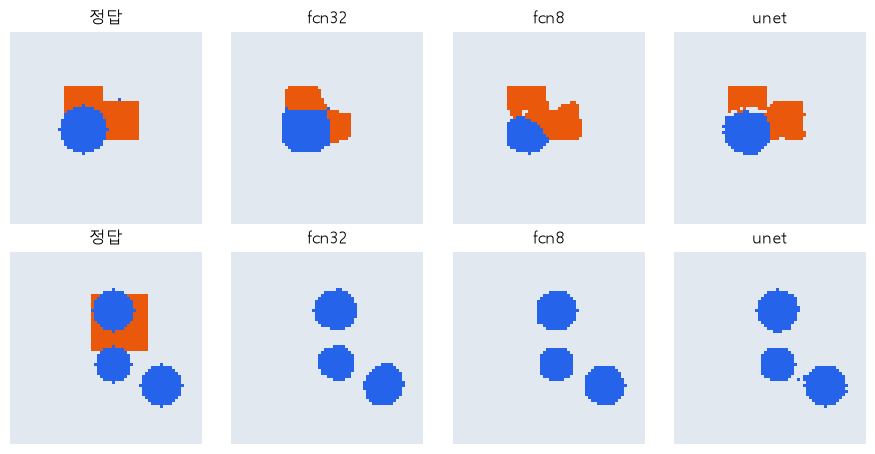

In [36]:
# ---------- 7. 종합 실습 ----------
# 왜 · 모델마다 같은 seed · 같은 절차로 학습하고 지표를 돌려받기 위해
def run(kind, epochs=30):                                                   # 학습 → 검증 지표
    torch.use_deterministic_algorithms(True)                                # 같은 환경에서 학습 동안 매번 같은 값
    torch.manual_seed(SEED)                                                 # 모델 초기값 같게
    net = Net(kind).to(device)                                              # 모델
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)                       # 같은 최적화
    order = torch.Generator().manual_seed(SEED)                             # 같은 섞는 순서
    for _ in range(epochs):                                                 # epoch 반복
        net.train()                                                         # 학습 모드
        for idx in torch.randperm(len(Xtr), generator=order).split(16):     # 16장씩
            out = net(Xtr[idx].to(device))                                  # (N, 3, H, W) 점수
            loss = F.cross_entropy(out.permute(0, 2, 3, 1).reshape(-1, 3),  # 픽셀을 한 줄로 펼친 CE
                                   Ytr[idx].to(device).reshape(-1))         # (GPU 고정 모드용)
            opt.zero_grad()                                                 # 기울기 지우기
            loss.backward()                                                 # 기울기 계산
            opt.step()                                                      # 갱신
    net.eval()                                                              # 평가 모드
    with torch.no_grad():                                                   # 기울기 불필요
        pred = net(Xva.to(device)).argmax(1).cpu()                          # 검증 예측
    torch.use_deterministic_algorithms(False)  # 3-1 MaxUnpool 등을 위해 끔
    iou = [((pred == c) & (Yva == c)).sum() / ((pred == c) | (Yva == c)).sum()  # 겹침 ÷ 합침
           for c in range(3)]
    e = edge_of(Yva)                                                        # 경계 픽셀
    return pred, torch.stack(iou).mean().item(), (pred[e] == Yva[e]).float().mean().item()  # 결과


# 왜 · 세 모델의 지표를 한곳에 모아 비교하기 위해
results = {}                                                       # 모델별 결과
for kind in ["fcn32", "fcn8", "unet"]:                             # 디코더만 다름
    pred, miou, edge = run(kind)                                   # 학습 · 평가
    results[kind] = pred                                           # 그림용
    print(f"{kind:6} | mIoU {miou:.4f} | 경계 정확도 {edge:.4f}")  # 비교


# 4단계: 검증 2장의 정답 · 세 모델 예측
# 왜 · 숫자로 본 차이를 같은 검증 이미지로 눈으로 확인하기 위해

plt.rcParams["font.family"] = "Malgun Gothic"                            # 한글 제목
cmap = ListedColormap(["#e2e8f0", "#2563eb", "#ea580c"])                 # 배경 · 원 · 사각형
fig, ax = plt.subplots(2, 4, figsize=(9, 4.6))                           # 2장 × (정답 + 모델 3개)
for r, i in enumerate([0, 3]):                                           # 검증 0번 · 3번
    panels = [("정답", Yva[i])] + [(k, results[k][i]) for k in results]  # 4칸
    for c, (title, m) in enumerate(panels):                              # 칸마다
        ax[r, c].imshow(m, cmap=cmap, vmin=0, vmax=2)                    # 번호별 색
        ax[r, c].set_title(title, fontsize=12)                           # 칸 제목
        ax[r, c].axis("off")                                             # 눈금 숨김
plt.tight_layout()                                                       # 간격 정리
plt.show()                                                               # 그림 표시